# Datavidia 11.0 — Task 1: Klasifikasi `status_penanganan`

**Metrik:** Macro F1 (7 kelas) · **Validasi:** Stratified 5-Fold OOF · **Model:** CatBoost + XGBoost (ensemble, GPU); LightGBM opsional

Notebook ini memuat seluruh pipeline: pemrosesan data, penggabungan 9 tabel, pembuatan fitur, pengembangan model,
training, ensemble, optimasi Macro F1, dan **inferensi tanpa retrain** (memuat file model tersimpan).

| Mode | Perilaku |
|---|---|
| `MODE = "inference"` *(default)* | Bangun fitur → muat model & tabel target-encoding dari `artifacts/` → `submission.csv` |
| `MODE = "train"` | Latih ulang semua model 5-fold dari nol (±1,5–3 jam/model di CPU; CatBoost/XGBoost bisa GPU) |

### Ringkasan pendekatan
1. **Fitur level paket** dari 9 tabel relasional: join 5 tabel master + agregasi 3 tabel log (scan, rute, invoice).
2. **Temuan kunci EDA:** label sangat *menempel* pada entitas: dua paket dari customer yang sama berlabel sama 44% kali
   (acak: 23%), kurir 35%. Maka sinyal terbesar ada di **efek laten customer / kurir / hub**, yang ditangkap lewat
   (a) statistik grup tanpa target dan (b) target encoding multikelas OOF yang dihitung **di dalam** fold.
3. **GBDT** multikelas, ensemble rata-rata geometrik proba, lalu **bobot per kelas** untuk memaksimalkan Macro F1
   (divalidasi nested supaya tidak overfit).

## Daftar Isi
0. Setup & Konfigurasi · 1. Load Data · 2. EDA Ringkas · 3. Join Tabel Lookup · 4. Agregasi Tabel 1:N ·
5. Feature Engineering Lanjutan · 6. Target Encoding OOF · 7. Validasi & Baseline · 8. Seleksi Fitur ·
9. Model & Training · 10. Ensemble · 11. Optimasi Macro F1 · 12. Analisis Error · 13. Simpan Artefak ·
14. Inferensi Tanpa Retrain · 15. Ringkasan & Dependensi

## 0. Setup & Konfigurasi
Semua yang bisa diubah ada di sel ini. `DATA_DIR` dideteksi otomatis (lokal `data/` atau Kaggle `/kaggle/input/...`).

In [1]:
import gc, json, os, random, time, warnings, platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
from scipy.stats import ks_2samp
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, log_loss, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pl.Config.set_tbl_rows(25); pl.Config.set_tbl_width_chars(160); pl.Config.set_fmt_str_lengths(40)

# ------------------------------------------------------------------ konfigurasi
MODE = "inference"                                   # "train" | "inference"
# (model, seed, residual TE?, override parameter) — kandidat ensemble; yang artefaknya tidak ada dilewati
MODEL_RUNS = [  # ensemble final (semua dengan residual TE customer, Section 6.1)
    ("cat", 11, True, {"learning_rate": 0.02, "iterations": 15000}),
    ("cat", 12, True, {"learning_rate": 0.04, "iterations": 10000}),
    ("xgb", 11, True, {}),
]
# Varian tanpa residual TE (hedge / pembanding), juga tersimpan di artifacts/:
#   ("cat", 1, False, {"learning_rate": 0.02, "iterations": 15000}), ("cat", 2, False, {"learning_rate": 0.04,
#   "iterations": 10000}), ("cat", 0, False, {}), ("xgb", 0, False, {})
SEED = 42                                            # seed pembagian fold
ART = "artifacts"                                    # model, tabel TE, OOF, proba test
CACHE = "cache"                                      # cache tabel fitur (parquet)
SUBMISSION_PATH = "submission.csv"


def find_data_dir() -> str:
    cands = [os.environ.get("DATA_DIR", ""), "data", "/kaggle/input/task-1-datavidia-11-0",
             "/kaggle/input/task-1-datavidia-11-0/Task-1-Datavidia-11.0"]
    for c in cands:
        if c and os.path.exists(os.path.join(c, "train", "shipments.csv")):
            return c
    raise FileNotFoundError("Data tidak ditemukan. Set env DATA_DIR atau jalankan data.py")


def set_seed(s: int):
    random.seed(s); np.random.seed(s); os.environ["PYTHONHASHSEED"] = str(s)


DATA_DIR = find_data_dir()
set_seed(SEED)
os.makedirs(ART, exist_ok=True); os.makedirs(CACHE, exist_ok=True)
print(f"MODE={MODE} | DATA_DIR={DATA_DIR} | Python {platform.python_version()}")
print({p: version(p) for p in ["numpy", "pandas", "polars", "scikit-learn", "lightgbm", "xgboost", "catboost"]})

MODE=inference | DATA_DIR=data | Python 3.12.16


{'numpy': '2.5.5', 'pandas': '3.1.1', 'polars': '2.1.0', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.4.1', 'catboost': '1.2.10'}


In [2]:
CLASSES = [
    "normal", "konfirmasi_alamat", "tertunda_operasional", "gagal_antar_awal",
    "retur_pengirim", "rusak_perjalanan", "klaim_hilang",
]


TARGET = "status_penanganan"


EVENTS = ["pickup", "sortasi", "transit", "keluar_hub", "upaya_antar", "selesai"]


DEVICES = ["scanner", "pda", "gerbang_otomatis", "manual"]


MODAS = ["darat", "laut", "udara", "kereta"]


INV_TYPES = ["pengiriman", "langganan", "klaim"]
K = len(CLASSES)
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}

## 1. Load Data & Optimasi Memori
Memakai **polars** (kolumnar, multi-thread): `scan_events` train ±6,8 juta baris terbaca dalam hitungan detik dan jauh
lebih hemat RAM daripada pandas. Strategi memori: **agregasi dulu di polars, baru join**, lalu matriks fitur
akhir dikonversi ke `float32`.

In [3]:
def read(data_dir: str, split: str, name: str) -> pl.DataFrame:
    return pl.read_csv(os.path.join(data_dir, split, f"{name}.csv"), infer_schema_length=20000)

In [4]:
TABLE_NAMES = ["shipments", "scan_events", "route_segments", "invoices",
               "customers", "couriers", "hubs", "service_packages", "promotions"]
t0 = time.time()
tables = {sp: {nm: read(DATA_DIR, sp, nm) for nm in TABLE_NAMES} for sp in ["train", "test"]}
print(f"load {time.time() - t0:.1f}s")
pl.DataFrame([dict(table=nm, train_rows=tables["train"][nm].height, test_rows=tables["test"][nm].height,
                   cols=tables["train"][nm].width, train_MB=round(tables["train"][nm].estimated_size("mb"), 1))
              for nm in TABLE_NAMES])

load 12.5s


table,train_rows,test_rows,cols,train_MB
str,i64,i64,i64,f64
"""shipments""",1243617,362245,38,388.4
"""scan_events""",6837111,1993132,8,513.7
"""route_segments""",2200148,641446,8,161.7
"""invoices""",1467722,427458,12,151.9
"""customers""",573841,573841,14,57.6
"""couriers""",23806,23806,11,2.0
"""hubs""",654,654,9,0.0
"""service_packages""",62,62,10,0.0
"""promotions""",34,34,6,0.0


**Sanity check:** kunci unik, semua paket punya baris di tabel log, tidak ada baris yatim, tabel master identik train vs test.

In [5]:
for sp in ["train", "test"]:
    sh = tables[sp]["shipments"]
    assert sh["shipment_id"].n_unique() == sh.height, "shipment_id tidak unik"
    ids = set(sh["shipment_id"])
    for nm in ["scan_events", "route_segments", "invoices"]:
        child = set(tables[sp][nm]["shipment_id"].unique())
        assert child == ids, f"{sp}/{nm}: coverage tidak penuh / ada baris yatim"
for nm in ["customers", "couriers", "hubs", "service_packages", "promotions"]:
    assert tables["train"][nm].equals(tables["test"][nm]), f"{nm} berbeda train vs test"
cov = {c: tables["test"]["shipments"][c].is_in(tables["train"]["shipments"][c].implode()).mean()
       for c in ["customer_id", "courier_id", "hub_id", "kota_asal", "kota_tujuan"]}
print("✓ semua sanity check lolos")
print("Proporsi ID test yang muncul di train:", {k: round(v, 3) for k, v in cov.items()})

✓ semua sanity check lolos
Proporsi ID test yang muncul di train: {'customer_id': 0.886, 'courier_id': 1.0, 'hub_id': 1.0, 'kota_asal': 1.0, 'kota_tujuan': 1.0}


## 2. EDA Ringkas
Fokus pada hal yang **mengubah keputusan pemodelan**: distribusi target, kualitas data, pergeseran train↔test,
dan, yang terpenting, di mana sinyalnya berada.

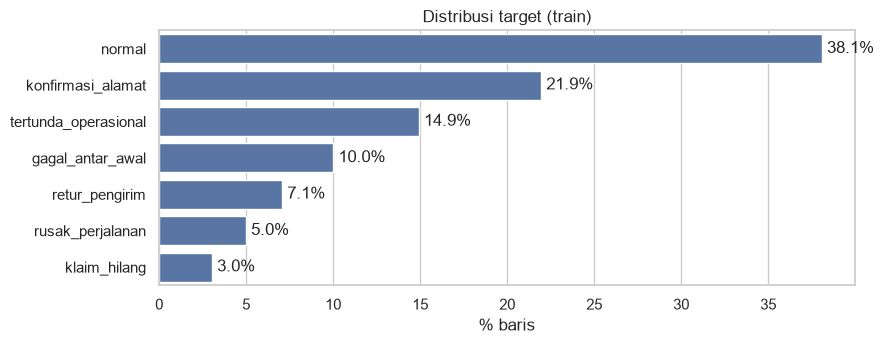

Rasio mayoritas : minoritas = 12.6 : 1 → perlu optimasi bobot kelas untuk Macro F1


In [6]:
y_str = tables["train"]["shipments"][TARGET]
dist = y_str.value_counts().with_columns((pl.col("count") / y_str.len() * 100).round(2).alias("pct")) \
            .sort("count", descending=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.barplot(data=dist.to_pandas(), y=TARGET, x="pct", ax=ax, color="#4C72B0")
for i, v in enumerate(dist["pct"]): ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set(title="Distribusi target (train)", xlabel="% baris", ylabel="")
plt.tight_layout(); plt.show()
print(f"Rasio mayoritas : minoritas = {dist['count'][0] / dist['count'][-1]:.1f} : 1 → perlu optimasi bobot kelas untuk Macro F1")

### 2.1 Missing value & pergeseran train ↔ test

In [7]:
rows = []
for nm in TABLE_NAMES:
    t = tables["train"][nm]
    for c, n in zip(t.columns, t.null_count().row(0)):
        if n: rows.append(dict(table=nm, col=c, missing_pct=round(n / t.height * 100, 2)))
display(pl.DataFrame(rows))

sh_tr = tables["train"]["shipments"]
print("Missing volume_l per kelas (%):",
      sh_tr.group_by(TARGET).agg((pl.col("volume_l").is_null().mean() * 100).round(2)).sort(TARGET).rows())

num_cols = [c for c, t in sh_tr.schema.items() if t.is_numeric()]
rng = np.random.default_rng(0)
ks = sorted(((ks_2samp(rng.choice(sh_tr[c].drop_nulls().to_numpy(), 100_000),
                       rng.choice(tables["test"]["shipments"][c].drop_nulls().to_numpy(), 100_000)).statistic, c)
             for c in num_cols), reverse=True)
print("KS statistic train vs test (terbesar):", [(c, round(s, 3)) for s, c in ks[:5]])

table,col,missing_pct
str,str,f64
"""shipments""","""volume_l""",2.98
"""route_segments""","""durasi_jam""",2.0
"""invoices""","""discount""",42.4
"""customers""","""credit_score""",1.99
"""couriers""","""courier_score""",1.08


Missing volume_l per kelas (%): [('gagal_antar_awal', 2.99), ('klaim_hilang', 2.89), ('konfirmasi_alamat', 3.03), ('normal', 2.95), ('retur_pengirim', 2.93), ('rusak_perjalanan', 2.98), ('tertunda_operasional', 3.0)]


KS statistic train vs test (terbesar): [('ship_month', np.float64(0.031)), ('indeks_waktu_proses', np.float64(0.007)), ('distance_km', np.float64(0.006)), ('weight_kg', np.float64(0.006)), ('varian_cuaca_rute', np.float64(0.006))]


Missing sedikit dan **tidak informatif** (proporsinya rata antar kelas), dan GBDT menanganinya secara native.
KS hampir semua kolom < 0,01. Pengecualiannya **`ship_month`** (KS ±0,03), yang diperiksa lebih dalam di bawah.

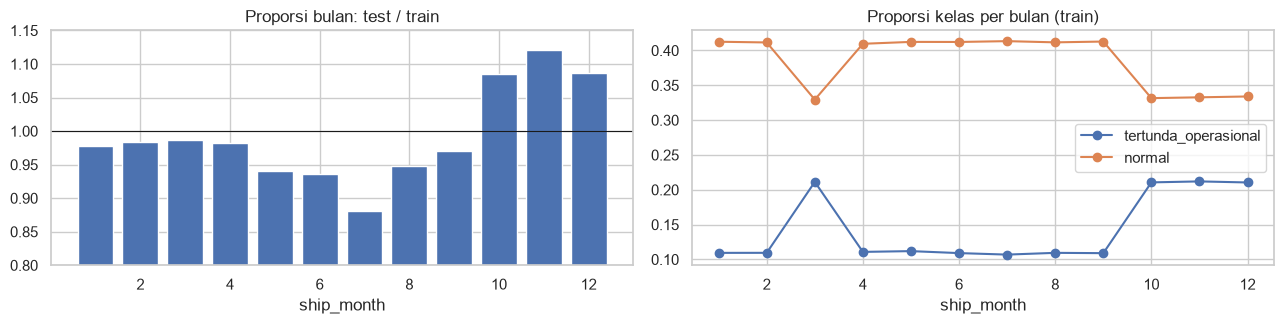

ship_month,p_normal,p_tertunda,rasio_test_train
i64,f64,f64,f64
1,0.413,0.109,0.978
2,0.411,0.109,0.984
3,0.329,0.211,0.987
4,0.41,0.111,0.982
5,0.412,0.112,0.941
6,0.412,0.109,0.936
7,0.413,0.107,0.881
8,0.412,0.109,0.948
9,0.413,0.109,0.97


In [8]:
mon = (sh_tr.group_by("ship_month").agg(pl.len().alias("n_train"),
                                         (pl.col(TARGET) == "normal").mean().alias("p_normal"),
                                         (pl.col(TARGET) == "tertunda_operasional").mean().alias("p_tertunda"))
       .join(tables["test"]["shipments"].group_by("ship_month").agg(pl.len().alias("n_test")), on="ship_month")
       .with_columns((pl.col("n_test") / pl.col("n_test").sum()) / (pl.col("n_train") / pl.col("n_train").sum()))
       .rename({"n_test": "rasio_test_train"}).drop("n_train").sort("ship_month"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].bar(mon["ship_month"], mon["rasio_test_train"], color="#4C72B0"); ax[0].axhline(1, color="k", lw=.8)
ax[0].set(title="Proporsi bulan: test / train", xlabel="ship_month", ylim=(0.8, 1.15))
ax[1].plot(mon["ship_month"], mon["p_tertunda"], "o-", label="tertunda_operasional")
ax[1].plot(mon["ship_month"], mon["p_normal"], "o-", label="normal")
ax[1].set(title="Proporsi kelas per bulan (train)", xlabel="ship_month"); ax[1].legend()
plt.tight_layout(); plt.show()
mon.with_columns(pl.exclude("ship_month").round(3))

**Temuan:** split train/test **tidak sepenuhnya acak** terhadap bulan. Test kelebihan bulan Okt–Des (rasio 1,08–1,12)
dan kekurangan Mei–Agt (0,88–0,95). Bulan **3, 10, 11, 12 adalah musim sibuk**: `tertunda_operasional` naik dari
±11% menjadi ±21%. Artinya prior kelas di test sedikit bergeser. Model tetap memakai `ship_month` sebagai fitur;
dampak pergeseran ini terhadap bobot kelas diuji di Section 11 (hasilnya: dapat diabaikan).
Untuk semua kolom lain, Stratified K-Fold tetap skema validasi yang tepat (lihat *adversarial validation* di Section 7).

### 2.2 Temuan kunci: label menempel pada entitas

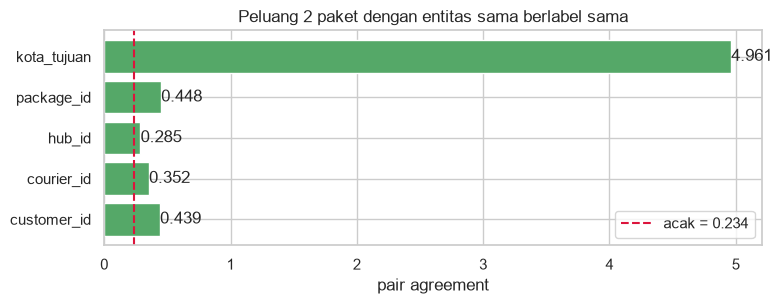

Paket per customer (train): [('mean', 2.447650594584381), ('50%', 2.0), ('max', 13.0)]


In [9]:
def pair_agreement(df: pl.DataFrame, key: str) -> float:
    """P(dua paket acak dengan `key` yang sama punya label sama)."""
    g = df.group_by(key, TARGET).len()
    n = df.group_by(key).len()
    return float((g["len"] * (g["len"] - 1)).sum() / (n["len"] * (n["len"] - 1)).sum())

p = sh_tr[TARGET].value_counts()["count"].to_numpy() / sh_tr.height
base = float((p ** 2).sum())
agree = {k: pair_agreement(sh_tr, k) for k in ["customer_id", "courier_id", "hub_id", "package_id", "kota_tujuan"]}
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(list(agree), list(agree.values()), color="#55A868")
ax.axvline(base, color="crimson", ls="--", label=f"acak = {base:.3f}")
for i, v in enumerate(agree.values()): ax.text(v + 0.003, i, f"{v:.3f}", va="center")
ax.set(title="Peluang 2 paket dengan entitas sama berlabel sama", xlabel="pair agreement"); ax.legend()
plt.tight_layout(); plt.show()
print("Paket per customer (train):", sh_tr.group_by("customer_id").len()["len"].describe().filter(
      pl.col("statistic").is_in(["mean", "50%", "max"])).rows())

**Implikasi:** customer (44% vs 23% acak) dan kurir (35%) punya *kecenderungan laten* yang kuat.
Karena 88,6% customer test juga ada di train, riwayat label mereka (via **target encoding OOF**) dan profil perilaku
mereka (via **statistik grup**, misalnya rata-rata gap scan semua paket milik seorang kurir) menjadi fitur paling penting.
Satu customer rata-rata hanya punya ±2,4 paket, jadi smoothing TE customer harus **kecil**.

### 2.3 Sinyal dari tabel log per kelas

In [10]:
sc = tables["train"]["scan_events"]
scan_cls = (sc.group_by("shipment_id").agg(
                (pl.col("event_type") == "upaya_antar").sum().alias("n_upaya_antar"),
                pl.col("gap_hours").mean().alias("gap_mean"), pl.col("scan_quality").mean().alias("quality_mean"),
                pl.col("is_manual").mean().alias("manual_rate"))
            .join(sh_tr.select("shipment_id", TARGET), on="shipment_id")
            .group_by(TARGET).agg(pl.exclude("shipment_id").mean().round(3)))
inv_cls = (tables["train"]["invoices"].group_by("shipment_id")
           .agg((pl.col("invoice_type") == "klaim").sum().alias("n_inv_klaim"))
           .join(sh_tr.select("shipment_id", TARGET), on="shipment_id")
           .group_by(TARGET).agg(pl.col("n_inv_klaim").mean().round(3)))
rt_cls = (tables["train"]["route_segments"].group_by("shipment_id")
          .agg(pl.len().alias("n_kaki"), pl.col("durasi_jam").mean().alias("durasi_mean"))
          .join(sh_tr.select("shipment_id", TARGET), on="shipment_id")
          .group_by(TARGET).agg(pl.exclude("shipment_id").mean().round(3)))
summary_cls = scan_cls.join(inv_cls, on=TARGET).join(rt_cls, on=TARGET) \
    .with_columns(pl.col(TARGET).replace_strict(CLS_IDX).alias("_o")).sort("_o").drop("_o")
summary_cls

status_penanganan,n_upaya_antar,gap_mean,quality_mean,manual_rate,n_inv_klaim,n_kaki,durasi_mean
str,f64,f64,f64,f64,f64,f64,f64
"""normal""",1.308,7.564,3.791,0.15,0.163,1.759,14.646
"""konfirmasi_alamat""",1.886,8.229,3.653,0.175,0.162,1.766,16.335
"""tertunda_operasional""",1.389,11.403,3.582,0.189,0.162,1.753,22.195
"""gagal_antar_awal""",1.582,8.067,3.398,0.222,0.149,1.733,15.749
"""retur_pengirim""",1.513,8.193,3.589,0.187,0.372,1.753,16.269
"""rusak_perjalanan""",1.341,7.96,3.092,0.278,0.152,2.019,17.977
"""klaim_hilang""",1.351,8.08,3.625,0.181,0.324,1.746,15.905


Pola sesuai intuisi domain: `upaya_antar` banyak → konfirmasi alamat / gagal antar; `gap` & durasi rute besar →
tertunda; kualitas scan rendah + scan manual → rusak; invoice `klaim` → retur & klaim hilang.
Perbedaannya **nyata tapi tipis** di level paket, sehingga diperlukan fitur level entitas.

### 2.4 Kolom yang dicurigai noise

In [11]:
def eta_squared(df: pl.DataFrame, col: str) -> float:
    d = df.select(pl.col(col).cast(pl.Float64), TARGET).drop_nulls()
    mu = d[col].mean()
    g = d.group_by(TARGET).agg(pl.col(col).mean().alias("m"), pl.len().alias("n"))
    return float(((g["m"] - mu) ** 2 * g["n"]).sum() / ((d[col] - mu) ** 2).sum())

eta = sorted(((eta_squared(sh_tr, c), c) for c in num_cols), reverse=True)
print("η² terbesar :", [(c, round(v, 4)) for v, c in eta[:6]])
print("η² ≈ 0      :", [c for v, c in eta if v < 1e-4])

η² terbesar : [('jumlah_catatan', 0.0643), ('declared_value', 0.0589), ('distance_km', 0.0348), ('flag_alamat_baru', 0.0128), ('ship_month', 0.0058), ('is_cod', 0.0007)]
η² ≈ 0      : ['skor_kualitas_cek', 'insurance_opt', 'fragility_flag', 'qty_items', 'weight_kg', 'is_promo', 'berat_volumetrik', 'indeks_rute_sekunder', 'indeks_waktu_proses', 'ship_dow', 'faktor_muatan_internal', 'coupon_count', 'volume_l', 'gift_wrap', 'skor_prioritas_kirim', 'ship_hour', 'varian_cuaca_rute']


Kolom dengan η² ≈ 0 (termasuk 6 kolom berdistribusi N(50, σ) seperti `skor_prioritas_kirim`) **tidak langsung dibuang**:
bisa jadi berguna lewat interaksi. Keputusannya diambil di Section 8 berdasarkan importance model.

## 3. Penggabungan Tabel Lookup (1:1)
`shipments` di-*left join* dengan 5 tabel master, dengan prefix kolom per tabel (`cust_`, `cour_`, `hub_`, `pkg_`, `promo_`).
Jumlah baris di-*assert* tidak berubah. Sekaligus dibuat fitur **relasi antar tabel** (kurir bertugas di hub yang
sama? region customer = tujuan? promo aktif di bulan kirim?), **rasio fisik** paket, dan **jam kirim vs jam operasional hub**.

In [12]:
def prefix(df: pl.DataFrame, p: str, key: str) -> pl.DataFrame:
    return df.rename({c: f"{p}{c}" for c in df.columns if c != key})


def join_lookups(sh: pl.DataFrame, tables: dict[str, pl.DataFrame]) -> pl.DataFrame:
    n = sh.height
    out = (
        sh.join(prefix(tables["customers"], "cust_", "customer_id"), on="customer_id", how="left", maintain_order="left")
        .join(prefix(tables["couriers"], "cour_", "courier_id"), on="courier_id", how="left", maintain_order="left")
        .join(prefix(tables["hubs"], "hub_", "hub_id"), on="hub_id", how="left", maintain_order="left")
        .join(prefix(tables["service_packages"], "pkg_", "package_id"), on="package_id", how="left", maintain_order="left")
        .join(prefix(tables["promotions"], "promo_", "promo_id"), on="promo_id", how="left", maintain_order="left")
    )
    assert out.height == n, "join lookup mengubah jumlah baris!"
    m = pl.col("ship_month")
    b, e = pl.col("promo_bulan_mulai"), pl.col("promo_bulan_akhir")
    out = out.with_columns(
        # relasi antar tabel
        (pl.col("cour_hub_id") == pl.col("hub_id")).cast(pl.Int8).alias("rel_cour_same_hub"),
        (pl.col("cust_region") == pl.col("dest_region")).cast(pl.Int8).alias("rel_cust_region_eq_dest"),
        (pl.col("hub_region") == pl.col("dest_region")).cast(pl.Int8).alias("rel_hub_region_eq_dest"),
        (pl.col("hub_region") == pl.col("cust_region")).cast(pl.Int8).alias("rel_hub_region_eq_cust"),
        (pl.col("kota_asal") == pl.col("kota_tujuan")).cast(pl.Int8).alias("rel_same_city"),
        pl.when(pl.col("promo_id") == "TANPA_PROMO").then(None)
        .when(b <= e).then(((m >= b) & (m <= e)).cast(pl.Int8))
        .otherwise(((m >= b) | (m <= e)).cast(pl.Int8)).alias("rel_promo_active"),
        # rasio / fisika paket
        (pl.col("declared_value") / pl.col("weight_kg").clip(0.01)).alias("r_value_per_kg"),
        (pl.col("berat_volumetrik") / pl.col("weight_kg").clip(0.01)).alias("r_volw_per_w"),
        (pl.col("volume_l") / pl.col("weight_kg").clip(0.01)).alias("r_vol_per_w"),
        (pl.max_horizontal("weight_kg", "berat_volumetrik") / pl.col("pkg_max_weight_kg")).alias("r_w_over_pkgmax"),
        (pl.max_horizontal("weight_kg", "berat_volumetrik") / pl.col("cour_kapasitas_muatan_kg")).alias("r_w_over_courcap"),
        (pl.col("distance_km") / pl.col("pkg_estimasi_hari").clip(1)).alias("r_km_per_estday"),
        (pl.col("declared_value") / pl.col("qty_items").clip(1)).alias("r_value_per_item"),
        # jam kirim vs jam operasional hub
        ((pl.col("ship_hour") < pl.col("hub_jam_buka")) | (pl.col("ship_hour") >= pl.col("hub_jam_tutup"))).cast(pl.Int8).alias("t_outside_hub_hours"),
        (pl.col("hub_jam_tutup") - pl.col("hub_jam_buka")).alias("t_hub_open_len"),
        (pl.col("hub_jam_tutup") - pl.col("ship_hour")).alias("t_hours_to_close"),
        (pl.col("hub_density_index") / pl.col("hub_capacity_index").clip(0.01)).alias("r_hub_load"),
        (pl.col("fragility_flag") * pl.col("pkg_fragile_score")).alias("x_fragile"),
        (pl.col("flag_alamat_baru") + pl.col("jumlah_catatan")).alias("x_addr_risk"),
        (pl.col("kota_asal") + "_" + pl.col("kota_tujuan")).alias("route_pair"),
    )
    return out

In [13]:
lookups = {k: tables["train"][k] for k in ["customers", "couriers", "hubs", "service_packages", "promotions"]}
_demo = join_lookups(tables["train"]["shipments"], lookups)
print(_demo.shape)
_demo.select("shipment_id", "rel_cour_same_hub", "rel_cust_region_eq_dest", "rel_promo_active",
             "r_value_per_kg", "t_outside_hub_hours", "route_pair").head(5)

(1243617, 103)


shipment_id,rel_cour_same_hub,rel_cust_region_eq_dest,rel_promo_active,r_value_per_kg,t_outside_hub_hours,route_pair
str,i8,i8,i8,f64,i8,str
"""SHP-AHSVFB3R""",1,0,null,4266.666667,0,"""banyuwangi_jayapura"""
"""SHP-FUWWVBCQ""",1,0,0,15753.424658,0,"""manado_palu"""
"""SHP-9EBN7MB9""",1,0,null,36060.606061,0,"""bandung_solo"""
"""SHP-5LK9F3MX""",1,0,null,20545.073375,0,"""surabaya_pekanbaru"""
"""SHP-6XV4H3CP""",1,0,0,26543.209877,0,"""kudus_purwokerto"""


## 4. Agregasi Tabel 1:N
Setiap tabel log diringkas menjadi **1 baris per `shipment_id`**:

| Tabel | Fitur |
|---|---|
| `scan_events` | jumlah & proporsi per `event_type`; `gap_hours` sum/mean/max/min/std (total & per event); `scan_quality` mean/min/max/std & jumlah scan berkualitas rendah; scan manual; per `device_type`; **urutan**: event terakhir, gap & kualitas scan pertama/terakhir, posisi `upaya_antar` pertama, jumlah perpindahan event |
| `route_segments` | jumlah kaki; jarak, durasi, biaya (sum/max/mean); kecepatan; biaya/km; jumlah & durasi per moda; moda pertama/terakhir; hub unik |
| `invoices` | jumlah & nominal per tipe (`pengiriman`/`langganan`/**`klaim`**); diskon, pajak; `days_to_pay`; penalti; status bayar |

Urutan scan = urutan baris di file (sudah diverifikasi: baris tiap paket bersebelahan dan selalu diawali `pickup`).

In [14]:
def agg_scan(sc: pl.DataFrame) -> pl.DataFrame:
    sc = sc.with_columns(pl.int_range(pl.len()).over("shipment_id").alias("pos"))
    et, g, q = pl.col("event_type"), pl.col("gap_hours"), pl.col("scan_quality")
    aggs = [
        pl.len().alias("sc_n"),
        g.sum().alias("sc_gap_sum"), g.mean().alias("sc_gap_mean"), g.max().alias("sc_gap_max"),
        g.min().alias("sc_gap_min"), g.std().alias("sc_gap_std"),
        q.mean().alias("sc_q_mean"), q.min().alias("sc_q_min"), q.max().alias("sc_q_max"), q.std().alias("sc_q_std"),
        (q <= 2).sum().alias("sc_q_low_n"), (q == 1).sum().alias("sc_q1_n"),
        pl.col("is_manual").sum().alias("sc_manual_n"), pl.col("is_manual").mean().alias("sc_manual_rate"),
        et.last().alias("sc_last_event"),
        g.last().alias("sc_last_gap"), g.first().alias("sc_first_gap"),
        q.last().alias("sc_last_q"), q.first().alias("sc_first_q"),
        pl.col("pos").filter(et == "upaya_antar").min().alias("sc_first_upaya_pos"),
        et.n_unique().alias("sc_n_unique_event"),
        (et != et.shift(1)).sum().alias("sc_n_switch"),
    ]
    for e in EVENTS:
        m = et == e
        aggs += [
            m.sum().alias(f"sc_n_{e}"),
            g.filter(m).sum().alias(f"sc_gap_sum_{e}"),
            g.filter(m).max().alias(f"sc_gap_max_{e}"),
            q.filter(m).mean().alias(f"sc_q_mean_{e}"),
            pl.col("is_manual").filter(m).sum().alias(f"sc_manual_{e}"),
        ]
    for d in DEVICES:
        m = pl.col("device_type") == d
        aggs += [m.sum().alias(f"sc_dev_{d}"), q.filter(m).mean().alias(f"sc_q_dev_{d}")]
    out = sc.group_by("shipment_id").agg(aggs)
    out = out.with_columns(
        (pl.col("sc_n_selesai") > 0).cast(pl.Int8).alias("sc_has_selesai"),
        (pl.col("sc_n_upaya_antar") / pl.col("sc_n")).alias("sc_upaya_frac"),
        (pl.col("sc_gap_max") / pl.col("sc_gap_mean").clip(0.01)).alias("sc_gap_peak_ratio"),
        (pl.col("sc_n_upaya_antar") - pl.col("sc_n_selesai")).alias("sc_upaya_minus_selesai"),
        (pl.col("sc_n_sortasi") + pl.col("sc_n_transit") + pl.col("sc_n_keluar_hub")).alias("sc_n_mid"),
    )
    return out


def agg_route(rs: pl.DataFrame) -> pl.DataFrame:
    rs = rs.sort(["shipment_id", "urutan"])
    d, t, c, j = pl.col("durasi_jam"), pl.col("biaya_segmen"), pl.col("moda"), pl.col("jarak_segmen_km")
    aggs = [
        pl.len().alias("rt_n"),
        j.sum().alias("rt_km_sum"), j.max().alias("rt_km_max"),
        d.sum().alias("rt_dur_sum"), d.max().alias("rt_dur_max"), d.mean().alias("rt_dur_mean"),
        d.null_count().alias("rt_dur_null"),
        t.sum().alias("rt_cost_sum"), t.max().alias("rt_cost_max"),
        (j / d.clip(0.01)).mean().alias("rt_speed_mean"), (j / d.clip(0.01)).min().alias("rt_speed_min"),
        (t / j.clip(0.1)).mean().alias("rt_cost_per_km"),
        pl.col("segmen_hub_id").n_unique().alias("rt_n_hub"),
        c.first().alias("rt_first_moda"), c.last().alias("rt_last_moda"),
        c.n_unique().alias("rt_n_moda"),
        pl.col("segmen_hub_id").first().alias("rt_first_hub"),
        pl.col("segmen_hub_id").last().alias("rt_last_hub"),
    ]
    for m in MODAS:
        f = c == m
        aggs += [f.sum().alias(f"rt_n_{m}"), d.filter(f).sum().alias(f"rt_dur_{m}"), j.filter(f).sum().alias(f"rt_km_{m}")]
    out = rs.group_by("shipment_id").agg(aggs)
    return out.with_columns((pl.col("rt_km_sum") / pl.col("rt_dur_sum").clip(0.01)).alias("rt_speed_total"))


def agg_invoice(inv: pl.DataFrame) -> pl.DataFrame:
    it, a = pl.col("invoice_type"), pl.col("amount")
    aggs = [
        pl.len().alias("iv_n"), a.sum().alias("iv_amount_sum"), a.max().alias("iv_amount_max"),
        pl.col("discount").sum().alias("iv_disc_sum"), pl.col("discount").null_count().alias("iv_disc_null"),
        pl.col("tax").sum().alias("iv_tax_sum"),
        pl.col("days_to_pay").mean().alias("iv_dtp_mean"), pl.col("days_to_pay").max().alias("iv_dtp_max"),
        pl.col("is_penalty").sum().alias("iv_penalty"),
        pl.col("issued_month").min().alias("iv_month_min"), pl.col("issued_month").max().alias("iv_month_max"),
        pl.col("payment_method").first().alias("iv_pay_method"),
        pl.col("payment_status").first().alias("iv_pay_status_first"),
    ]
    for ty in INV_TYPES:
        f = it == ty
        aggs += [
            f.sum().alias(f"iv_n_{ty}"), a.filter(f).sum().alias(f"iv_amt_{ty}"),
            pl.col("days_to_pay").filter(f).max().alias(f"iv_dtp_{ty}"),
            pl.col("discount").filter(f).sum().alias(f"iv_disc_{ty}"),
        ]
    for st in ["lunas", "tertunda", "gagal"]:
        aggs.append((pl.col("payment_status") == st).sum().alias(f"iv_st_{st}"))
    return inv.group_by("shipment_id").agg(aggs)

In [15]:
_ids = tables["train"]["shipments"]["shipment_id"].head(20_000).implode()
for fn, nm in [(agg_scan, "scan_events"), (agg_route, "route_segments"), (agg_invoice, "invoices")]:
    a = fn(tables["train"][nm].filter(pl.col("shipment_id").is_in(_ids)))
    print(f"{fn.__name__:12s} → {a.shape[1] - 1:3d} fitur | contoh kolom: {a.columns[1:7]}")

agg_scan     →  65 fitur | contoh kolom: ['sc_n', 'sc_gap_sum', 'sc_gap_mean', 'sc_gap_max', 'sc_gap_min', 'sc_gap_std']


agg_route    →  31 fitur | contoh kolom: ['rt_n', 'rt_km_sum', 'rt_km_max', 'rt_dur_sum', 'rt_dur_max', 'rt_dur_mean']
agg_invoice  →  28 fitur | contoh kolom: ['iv_n', 'iv_amount_sum', 'iv_amount_max', 'iv_disc_sum', 'iv_disc_null', 'iv_tax_sum']


## 5. Feature Engineering Lanjutan
Fungsi `build()` menyatukan semuanya untuk train **dan** test dengan kode yang sama, lalu menambahkan:

* **Fitur lintas tabel:** durasi rute aktual vs `estimasi_hari` paket, total gap scan vs estimasi, selisih jarak
  segmen vs `distance_km`, nominal klaim / nilai barang, biaya rute / nilai barang.
* **Frequency encoding** ID (customer, kurir, hub, kota, rute).
* **Statistik grup tanpa target** untuk customer (`gc_`), kurir (`gk_`), hub (`gh_`), rute (`gr_`), paket layanan (`gp_`):
  rata-rata 26 fitur perilaku di level entitas + deviasi paket dari rata-rata entitasnya. Ini **profil laten**
  entitas (misalnya kurir yang scan-nya sering telat / berkualitas rendah). Dihitung di train+test tanpa label,
  jadi **tidak ada leakage**.

ID kardinalitas tinggi (`customer_id`, `courier_id`, ...) **tidak** dipakai mentah sebagai fitur.

In [16]:
CAT_COLS = [
    "hub_id", "package_id", "promo_id", "channel", "pickup_type", "goods_category", "dest_region",
    "kota_asal", "kota_tujuan", "cust_region", "cust_segment", "cust_preferred_payment", "cust_loyalty_tier",
    "cust_kota_tipe", "cust_metode_notifikasi", "cour_vehicle_type", "cour_contract_type", "cour_shift_code",
    "hub_region", "hub_hub_type", "pkg_speed_class", "pkg_handling_class", "promo_nama_promo", "promo_tipe_promo",
    "sc_last_event", "rt_first_moda", "rt_last_moda", "iv_pay_method", "iv_pay_status_first",
]


ID_COLS = ["shipment_id", "customer_id", "courier_id", "cour_hub_id", "route_pair", "rt_first_hub", "rt_last_hub"]


FEAT_FILE = "features_v2.parquet"


def build(data_dir: str, cache_dir: str | None = None, tables: dict | None = None) -> pl.DataFrame:
    """Bangun tabel fitur gabungan train+test (kolom `is_test`). Tanpa target leakage.

    `tables` (opsional): {split: {nama_tabel: DataFrame}} yang sudah di-load; kalau None dibaca dari CSV.
    """
    if cache_dir and os.path.exists(os.path.join(cache_dir, FEAT_FILE)):
        return pl.read_parquet(os.path.join(cache_dir, FEAT_FILE))
    get = (lambda sp, nm: tables[sp][nm]) if tables else (lambda sp, nm: read(data_dir, sp, nm))
    lookups = {k: get("train", k) for k in ["customers", "couriers", "hubs", "service_packages", "promotions"]}
    parts = []
    for split in ["train", "test"]:
        sh = get(split, "shipments")
        df = join_lookups(sh, lookups)
        for fn, name in [(agg_scan, "scan_events"), (agg_route, "route_segments"), (agg_invoice, "invoices")]:
            a = fn(get(split, name))
            assert a["shipment_id"].n_unique() == a.height
            df = df.join(a, on="shipment_id", how="left", maintain_order="left")
        assert df.height == sh.height
        df = df.with_columns(pl.lit(split == "test").alias("is_test"))
        if TARGET not in df.columns:
            df = df.with_columns(pl.lit(None, dtype=pl.String).alias(TARGET))
        parts.append(df)
    df = pl.concat(parts, how="diagonal_relaxed")

    # fitur turunan lintas tabel
    df = df.with_columns(
        (pl.col("rt_dur_sum") / (pl.col("pkg_estimasi_hari") * 24)).alias("x_dur_vs_est"),
        (pl.col("sc_gap_sum") / (pl.col("pkg_estimasi_hari") * 24)).alias("x_gap_vs_est"),
        (pl.col("rt_km_sum") - pl.col("distance_km")).alias("x_km_diff"),
        (pl.col("iv_amt_klaim") / pl.col("declared_value").clip(1)).alias("x_claim_over_value"),
        (pl.col("rt_cost_sum") / pl.col("declared_value").clip(1)).alias("x_cost_over_value"),
        (pl.col("iv_month_min") - pl.col("ship_month")).alias("x_inv_month_lag"),
        (pl.col("rt_last_hub") != pl.col("hub_id")).cast(pl.Int8).alias("x_last_hub_diff"),
    )

    # frequency encoding (train+test, tanpa target â†’ aman)
    for col in ["customer_id", "courier_id", "hub_id", "kota_asal", "kota_tujuan", "route_pair", "package_id",
                "rt_last_hub"]:
        df = df.with_columns(pl.len().over(col).alias(f"fq_{col}"))

    # statistik grup tanpa target: perilaku customer / kurir / hub rata-rata
    grp_feats = ["sc_n_upaya_antar", "sc_gap_mean", "sc_q_mean", "sc_manual_rate", "declared_value",
                 "jumlah_catatan", "flag_alamat_baru", "iv_n_klaim", "rt_dur_sum", "is_cod", "distance_km",
                 "sc_gap_max", "sc_q_min", "sc_q_low_n", "sc_n", "sc_n_selesai", "iv_dtp_mean", "iv_amt_klaim",
                 "rt_n", "rt_n_udara", "rt_n_laut", "rt_speed_total", "iv_st_tertunda", "x_dur_vs_est",
                 "weight_kg", "ship_month"]
    for key, p in [("customer_id", "gc"), ("courier_id", "gk"), ("hub_id", "gh"), ("route_pair", "gr"),
                   ("package_id", "gp")]:
        exprs = [pl.col("sc_gap_mean").std().over(key).alias(f"{p}_sc_gap_mean_std"),
                 pl.col("sc_q_mean").std().over(key).alias(f"{p}_sc_q_mean_std")]
        for f in grp_feats:
            mean = pl.col(f).mean().over(key)
            exprs += [mean.alias(f"{p}_{f}_mean"), (pl.col(f) - mean).alias(f"{p}_{f}_dev")]
        df = df.with_columns(exprs)

    # kategori
    df = df.with_columns([pl.col(c).cast(pl.String).fill_null("NA") for c in CAT_COLS])
    if cache_dir:
        os.makedirs(cache_dir, exist_ok=True)
        df.write_parquet(os.path.join(cache_dir, FEAT_FILE))
    return df

In [17]:
t0 = time.time()
df = build(DATA_DIR, CACHE, tables)
n_tr = tables["train"]["shipments"].height
assert df.height == n_tr + tables["test"]["shipments"].height
assert (df["shipment_id"][:n_tr] == tables["train"]["shipments"]["shipment_id"]).all()       # urutan terjaga
assert (df["shipment_id"][n_tr:] == tables["test"]["shipments"]["shipment_id"]).all()
print(f"tabel fitur {df.shape} dibangun dalam {time.time() - t0:.0f}s, {df.estimated_size('gb'):.2f} GB")
groups = pd.Series([c.split("_")[0] if c.split("_")[0] in {"sc", "rt", "iv", "gc", "gk", "gh", "gr", "gp", "fq",
                    "cust", "cour", "hub", "pkg", "promo", "rel", "r", "t", "x"} else "shipments" for c in df.columns])
print(groups.value_counts().to_dict())
del tables, _demo, sc; gc.collect();

tabel fitur (1605862, 513) dibangun dalam 14s, 5.79 GB
{'sc': 65, 'gc': 54, 'gk': 54, 'gh': 54, 'gr': 54, 'gp': 54, 'shipments': 38, 'rt': 31, 'iv': 28, 'cust': 13, 'cour': 10, 'hub': 9, 'pkg': 9, 'x': 9, 'r': 8, 'fq': 8, 'promo': 6, 'rel': 6, 't': 3}


## 6. Target Encoding Multikelas OOF-safe ⚠️
Untuk setiap kunci, encoding = proporsi 7 kelas tersmoothing ke prior: $\hat p_k = \frac{n_k + m\,\pi_k}{n + m}$, plus jumlah sampel $n$.

**Skema anti-leakage (dua tingkat):**
1. Di **dalam** setiap fold model (outer fold *k*), TE untuk baris training dihitung dengan **inner 5-fold OOF**:
   sebuah baris tidak pernah melihat labelnya sendiri.
2. TE untuk baris validasi dan test dihitung dari **seluruh** bagian training fold *k* (tidak menyentuh label validasi).
3. Tabel TE tiap fold disimpan (`artifacts/te/`) → inference test memakai tabel yang sama persis dengan saat training.

Smoothing `m` disesuaikan dengan jumlah data per level: customer hanya ±2,4 paket → `m=2`; kurir ±52 paket → `m=10`;
kunci lain `m=30`.

In [18]:
def fit_te(codes: np.ndarray, y: np.ndarray, n_levels: int, k: int, m: float, prior: np.ndarray) -> np.ndarray:
    cnt = np.zeros((n_levels, k), dtype=np.float64)
    np.add.at(cnt, (codes, y), 1.0)
    n = cnt.sum(1, keepdims=True)
    return ((cnt + m * prior) / (n + m)).astype(np.float32), n.ravel()


def oof_te(codes: np.ndarray, y: np.ndarray, n_levels: int, k: int, m: float, n_splits: int = 5, seed: int = 0):
    """OOF encoding untuk baris (codes, y). Return (n, k) proba + (n,) count."""
    prior = np.bincount(y, minlength=k) / len(y)
    out = np.zeros((len(y), k), dtype=np.float32)
    cnt = np.zeros(len(y), dtype=np.float32)
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    for tr, va in skf.split(codes, y):
        tab, n = fit_te(codes[tr], y[tr], n_levels, k, m, prior)
        out[va] = tab[codes[va]]
        cnt[va] = n[codes[va]] * n_splits / (n_splits - 1)  # samakan skala dgn TE penuh
    return out, cnt


def encode_fold(codes_all: np.ndarray, y_all: np.ndarray, tr_idx: np.ndarray, apply_idx: list[np.ndarray],
                n_levels: int, k: int, m: float, seed: int = 0):
    """Untuk satu fold model: OOF-TE di bagian train, TE penuh (dari tr_idx) untuk set lain (valid/test).

    Return: (enc_train, [enc_apply...], table) â€” table disimpan untuk inference.
    """
    y_tr = y_all[tr_idx]
    enc_tr, n_tr = oof_te(codes_all[tr_idx], y_tr, n_levels, k, m, seed=seed)
    prior = np.bincount(y_tr, minlength=k) / len(y_tr)
    tab, n = fit_te(codes_all[tr_idx], y_tr, n_levels, k, m, prior)
    applied = [(tab[codes_all[i]], n[codes_all[i]].astype(np.float32)) for i in apply_idx]
    return (enc_tr, n_tr), applied, (tab, n.astype(np.float32))

In [19]:
TE_KEYS = {  # nama: (kolom, smoothing m)
    "customer_id": (["customer_id"], 2.0),
    "courier_id": (["courier_id"], 10.0),
    "hub_id": (["hub_id"], 30.0),
    "route_pair": (["route_pair"], 30.0),
    "hub_pkg": (["hub_id", "package_id"], 30.0),
    "hub_goods": (["hub_id", "goods_category"], 30.0),
    "kota_tujuan": (["kota_tujuan"], 30.0),
}


def te_codes(df: pl.DataFrame, keys: dict = TE_KEYS) -> dict[str, tuple[np.ndarray, int]]:
    out = {}
    for name, (cols, m) in keys.items():
        c = df.select(pl.struct(cols).rank("dense").cast(pl.Int64) - 1).to_series().to_numpy()
        out[name] = (c, int(c.max()) + 1, m)
    return out


def add_te(X_parts: list[pd.DataFrame], codes: dict, y: np.ndarray, tr_idx, other_idx: list,
           seed: int = 0, keep_tables: bool = False):
    """Tambahkan kolom TE ke X_train (OOF) dan ke X lain (TE penuh dari tr_idx)."""
    tables = {}
    Xtr, others = X_parts[0], X_parts[1:]
    for name, (c, nl, m) in codes.items():
        (etr, ntr), applied, tab = encode_fold(c, y, tr_idx, other_idx, nl, K, m, seed=seed)
        for j, cls in enumerate(CLASSES):
            Xtr[f"te_{name}_{cls}"] = etr[:, j]
        Xtr[f"te_{name}_n"] = ntr
        for Xo, (eo, no) in zip(others, applied):
            for j, cls in enumerate(CLASSES):
                Xo[f"te_{name}_{cls}"] = eo[:, j]
            Xo[f"te_{name}_n"] = no
        if keep_tables:
            tables[name] = tab
    return tables


def save_te_tables(df: pl.DataFrame, codes: dict, tables: dict, path_prefix: str, keys_def: dict = TE_KEYS,
                   col_prefix: str = "te"):
    """Simpan tabel TE (nilai kunci â†’ 7 nilai + n) supaya inference tidak perlu label train."""
    for name, (cols, _) in keys_def.items():
        tab, n = tables[name]
        keys = (df.select(cols).with_columns(pl.Series("_code", codes[name][0]))
                .unique("_code").sort("_code"))
        out = keys.with_columns(
            *[pl.Series(f"{col_prefix}_{name}_{c}", tab[keys["_code"].to_numpy(), j]) for j, c in enumerate(CLASSES)],
            pl.Series(f"{col_prefix}_{name}_n", n[keys["_code"].to_numpy()]),
        ).drop("_code")
        out.write_parquet(path_prefix.replace(".parquet", f"_{name}.parquet"))


def apply_te_tables(df: pl.DataFrame, X: pd.DataFrame, path_prefix: str, keys_def: dict = TE_KEYS) -> pd.DataFrame:
    """Inference: gabungkan tabel TE tersimpan ke baris df (urutan dipertahankan). Kunci tak dikenal â†’ NaN."""
    X = X.copy()
    for name, (cols, _) in keys_def.items():
        tab = pl.read_parquet(path_prefix.replace(".parquet", f"_{name}.parquet"))
        j = df.select(cols).join(tab, on=cols, how="left", maintain_order="left")
        assert j.height == df.height
        for c in tab.columns:
            if c not in cols:
                X[c] = j[c].to_numpy().astype(np.float32)
    return X

**Demo kenapa OOF wajib:** TE customer yang dihitung *in-sample* (baris melihat labelnya sendiri) terlihat sangat bagus, padahal itu ilusi.

In [20]:
_y = df.filter(~pl.col("is_test"))[TARGET].replace_strict(CLS_IDX).to_numpy()
_c = df.filter(~pl.col("is_test")).select(pl.col("customer_id").rank("dense").cast(pl.Int64) - 1).to_series().to_numpy()
_prior = np.bincount(_y, minlength=K) / len(_y)
_insample, _ = fit_te(_c, _y, _c.max() + 1, K, 2.0, _prior)
_oof, _ = oof_te(_c, _y, _c.max() + 1, K, 2.0)
_w = 1 / _prior  # koreksi prior supaya argmax tidak selalu 'normal'
print(f"Macro F1 argmax TE customer IN-SAMPLE (bocor): {f1_score(_y, (_insample[_c] * _w).argmax(1), average='macro'):.4f}")
print(f"Macro F1 argmax TE customer OOF (jujur)     : {f1_score(_y, (_oof * _w).argmax(1), average='macro'):.4f}")
del _c, _insample, _oof; gc.collect();

Macro F1 argmax TE customer IN-SAMPLE (bocor): 0.6208
Macro F1 argmax TE customer OOF (jujur)     : 0.2737


### 6.1 Residual target encoding customer (efek acak ala *mixed-effects*) ⭐
TE customer biasa = proporsi label paket lain milik customer. Masalahnya, label itu **tercampur efek fitur paket**:
paket lain berlabel `klaim_hilang` mungkin karena barangnya mahal, bukan karena customer-nya "rawan klaim".
Dengan rata-rata hanya ±2 paket/customer di train, campuran ini membuat estimasi kecenderungan customer bising.

Solusi (prinsip *mixed-effects* / GPBoost: tree-boosting + efek acak per grup, Sigrist 2022):
1. **Tahap A** — CatBoost 5-fold **tanpa** informasi label customer → proba OOF $\hat p^A$.
2. **Residual** $R_i = \text{onehot}(y_i) - \hat p^A_i$ = bagian label yang **tidak** dijelaskan fitur paket.
3. **Residual TE** customer = rata-rata $R$ paket lain milik customer, di-*shrink* ke 0: $\frac{\sum R}{n + m}$ (m=1),
   dihitung dengan skema OOF dua tingkat yang sama seperti TE biasa; tabelnya disimpan per fold (`te/rte_f*`).

Anti-leakage: baris validasi/test hanya memakai residual baris train-fold; model tahap A tidak pernah melihat
label customer, sehingga kebocoran yang tersisa hanya ke arah **konservatif** (mengecilkan sinyal).
Hasil eksperimen fold 0 (CatBoost lr 0,08): logloss **0,7847 → 0,7817**, Macro F1 (+bobot) **0,6225 → 0,6259**
— peningkatan terbesar di seluruh eksperimen.

In [21]:
def fit_resid(codes: np.ndarray, R: np.ndarray, n_levels: int, m: float):
    """Rata-rata residual (one-hot(y) âˆ’ proba model tanpa info entitas) per level, shrink ke 0 dengan m."""
    s = np.stack([np.bincount(codes, weights=R[:, j], minlength=n_levels) for j in range(R.shape[1])], 1)
    n = np.bincount(codes, minlength=n_levels).astype(np.float64)
    return (s / (n + m)[:, None]).astype(np.float32), n


def encode_fold_resid(codes_all: np.ndarray, R_all: np.ndarray, tr_idx: np.ndarray, apply_idx: list[np.ndarray],
                      n_levels: int, m: float, n_splits: int = 5, seed: int = 0):
    """Residual TE (efek acak entitas ala mixed-effects): OOF inner-fold untuk tr_idx, tabel penuh untuk set lain."""
    from sklearn.model_selection import KFold
    enc_tr = np.zeros((len(tr_idx), R_all.shape[1]), dtype=np.float32)
    n_tr = np.zeros(len(tr_idx), dtype=np.float32)
    for a, b in KFold(n_splits, shuffle=True, random_state=seed).split(tr_idx):
        tab, n = fit_resid(codes_all[tr_idx[a]], R_all[tr_idx[a]], n_levels, m)
        enc_tr[b] = tab[codes_all[tr_idx[b]]]
        n_tr[b] = n[codes_all[tr_idx[b]]] * n_splits / (n_splits - 1)
    tab, n = fit_resid(codes_all[tr_idx], R_all[tr_idx], n_levels, m)
    applied = [(tab[codes_all[i]], n[codes_all[i]].astype(np.float32)) for i in apply_idx]
    return (enc_tr, n_tr), applied, (tab, n.astype(np.float32))

In [22]:
RESID_KEYS = {"customer_id": (["customer_id"], 1.0)}


def stage_a_oof(X: pd.DataFrame, y_all: np.ndarray, tr_all: np.ndarray, folds: np.ndarray, df: pl.DataFrame,
                verbose: bool = True) -> np.ndarray:
    """Tahap A: OOF proba CatBoost (lr 0.08) tanpa TE berbasis customer. Fold sama dengan model utama."""
    import gc, json, time
    from catboost import CatBoostClassifier, Pool
    codes_a = te_codes(df, {k: v for k, v in TE_KEYS.items() if "customer_id" not in v[0]})
    params = dict(CAT_PARAMS, learning_rate=0.08, iterations=4000, verbose=0)
    oof = np.zeros((len(tr_all), K), dtype=np.float32)
    for k in range(int(folds.max()) + 1):
        t = time.time()
        tr_idx, va_idx = tr_all[folds != k], tr_all[folds == k]
        Xtr, Xva = X.iloc[tr_idx].copy(), X.iloc[va_idx].copy()
        add_te([Xtr, Xva], codes_a, y_all, tr_idx, [va_idx], seed=k)
        cats = [c for c in Xtr.columns if str(Xtr[c].dtype) == "category"]
        conv = lambda d: d.assign(**{c: d[c].astype(str) for c in cats})
        pva = Pool(conv(Xva), y_all[va_idx], cat_features=cats)
        m = CatBoostClassifier(**params, random_seed=k)
        m.fit(Pool(conv(Xtr), y_all[tr_idx], cat_features=cats), eval_set=pva, use_best_model=True)
        oof[folds == k] = m.predict_proba(pva)
        if verbose:
            print(json.dumps(dict(stage_a_fold=k, iters=m.get_best_iteration(),
                                  mins=round((time.time() - t) / 60, 1))), flush=True)
        del Xtr, Xva, m; gc.collect()
    return oof


def resid_matrix(y_all: np.ndarray, tr_all: np.ndarray, oof_a: np.ndarray) -> np.ndarray:
    R = np.zeros((len(y_all), K), dtype=np.float32)
    R[tr_all] = np.eye(K, dtype=np.float32)[y_all[tr_all]] - oof_a
    return R


def add_resid(X_parts: list[pd.DataFrame], rcodes: dict, R_all: np.ndarray, tr_idx, other_idx: list,
              seed: int = 0, keep_tables: bool = False):
    """Tambahkan kolom residual TE (rte_*) â€” OOF inner-fold untuk train, tabel penuh untuk set lain."""
    from te import encode_fold_resid
    tables = {}
    Xtr, others = X_parts[0], X_parts[1:]
    for name, (c, nl, m) in rcodes.items():
        (etr, ntr), applied, tab = encode_fold_resid(c, R_all, tr_idx, other_idx, nl, m, seed=seed)
        for j, cls in enumerate(CLASSES):
            Xtr[f"rte_{name}_{cls}"] = etr[:, j]
        Xtr[f"rte_{name}_n"] = ntr
        for Xo, (eo, no) in zip(others, applied):
            for j, cls in enumerate(CLASSES):
                Xo[f"rte_{name}_{cls}"] = eo[:, j]
            Xo[f"rte_{name}_n"] = no
        if keep_tables:
            tables[name] = tab
    return tables

## 7. Skema Validasi & Baseline
* `StratifiedKFold(5, shuffle=True, seed=42)`: fold yang **sama** untuk semua model (OOF bisa di-blend).
* Matriks fitur: kategori kardinalitas rendah → kategori native; kategori kardinalitas tinggi (`hub_id`, kota,
  paket, promo) → kode integer + TE (eksperimen menunjukkan kategori native ratusan level **overfit**).

In [23]:
def to_pandas_X(df: pl.DataFrame, drop: list[str] | None = None) -> pd.DataFrame:
    drop = set((drop or []) + ID_COLS + [TARGET, "is_test"])
    cols = [c for c in df.columns if c not in drop]
    pdf = df.select(cols).to_pandas()
    for c in cols:
        if c in CAT_COLS:
            pdf[c] = pdf[c].astype("category")
        elif pdf[c].dtype == bool:
            pdf[c] = pdf[c].astype(np.int8)
        else:
            pdf[c] = pdf[c].astype(np.float32)
    return pdf


HC_CATS = ["hub_id", "kota_asal", "kota_tujuan", "package_id", "promo_id"]


def prepare_matrix(df: pl.DataFrame):
    """X (pandas) untuk seluruh baris train+test, label (âˆ’1 untuk test), indeks train & test."""
    X = to_pandas_X(df)
    for c in HC_CATS:
        X[c] = X[c].cat.codes.astype(np.float32)
    is_test = df["is_test"].to_numpy()
    y_all = np.full(df.height, -1)
    y_all[~is_test] = (df.filter(~pl.col("is_test"))[TARGET]
                       .replace_strict({c: i for i, c in enumerate(CLASSES)}).to_numpy())
    return X, y_all, np.where(~is_test)[0], np.where(is_test)[0]


def make_folds(y: np.ndarray, n_splits: int = 5, seed: int = 42) -> np.ndarray:
    f = np.zeros(len(y), dtype=np.int8)
    for i, (_, va) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(y, y)):
        f[va] = i
    return f


def macro_f1(y, proba, w=None, sw=None) -> float:
    """Macro F1 dari argmax(proba * w). `sw` = bobot sampel (mis. koreksi pergeseran bulan trainâ†’test)."""
    p = proba if w is None else proba * w
    k = proba.shape[1]  # confusion matrix via bincount: identik dgn sklearn f1_score(macro), jauh lebih cepat
    cm = np.bincount(np.asarray(y) * k + p.argmax(1), weights=sw, minlength=k * k).reshape(k, k)
    tp, pred, true = np.diag(cm), cm.sum(0), cm.sum(1)
    denom = pred + true
    return float(np.mean(np.divide(2 * tp, denom, out=np.zeros(k), where=denom > 0)))

In [24]:
X, y_all, tr_all, te_all = prepare_matrix(df)
codes = te_codes(df)
folds = make_folds(y_all[tr_all], 5, SEED)
if os.path.exists(f"{ART}/folds.npy"):
    assert (np.load(f"{ART}/folds.npy") == folds).all(), "fold berbeda dengan saat training!"
y_tr = y_all[tr_all]
print(f"X: {X.shape} | train {len(tr_all):,} | test {len(te_all):,} | fold sizes {np.bincount(folds)}")
maj = np.zeros((len(y_tr), K)); maj[:, 0] = 1
print(f"Baseline tebak mayoritas ('normal'): Macro F1 = {macro_f1(y_tr, maj):.4f}")

X: (1605862, 504) | train 1,243,617 | test 362,245 | fold sizes [248724 248724 248723 248723 248723]
Baseline tebak mayoritas ('normal'): Macro F1 = 0.0788


**Adversarial validation:** bisakah model membedakan baris train vs test? AUC ≈ 0,5 → distribusi sama → CV lokal bisa dipercaya.

In [25]:
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(tr_all, 150_000, replace=False), rng.choice(te_all, 150_000, replace=False)])
is_t = np.r_[np.zeros(150_000), np.ones(150_000)]
Xa = X.iloc[idx].drop(columns=[c for c in X.columns if c.startswith("fq_")])  # frekuensi dihitung gabungan
aucs = []
for a, b in StratifiedKFold(3, shuffle=True, random_state=0).split(Xa, is_t):
    m = lgb.train(dict(objective="binary", learning_rate=0.1, num_leaves=63, verbose=-1, num_threads=os.cpu_count()),
                  lgb.Dataset(Xa.iloc[a], is_t[a]), 200)
    aucs.append(roc_auc_score(is_t[b], m.predict(Xa.iloc[b])))
print(f"Adversarial AUC = {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")
del Xa, m; gc.collect();

Adversarial AUC = 0.5249 ± 0.0006


### Log eksperimen (LightGBM, 1 fold holdout 20%, `lr=0.1`, dari `src/exp_lgb.py`)
Setiap perubahan diterima hanya jika **logloss** (metrik yang lebih stabil daripada F1) turun jelas.

| # | Perubahan | Fitur | Logloss | Macro F1 (argmax) | Macro F1 (+bobot kelas) | Keputusan |
|---|---|---:|---:|---:|---:|---|
| 0 | Baseline overview (300rb sampel, tanpa TE) | 160 | – | 0,4747 | 0,4782 | – |
| 1 | Data penuh + agregasi lengkap + TE OOF (m=30) | 356 | 0,8209 | 0,5979 | 0,6078 | ✅ |
| 2 | Smoothing TE per kunci (customer m=2, kurir m=10) | 356 | 0,8203 | 0,5987 | 0,6072 | ✅ (netral, lebih masuk akal) |
| 3 | Kategori kardinalitas tinggi → kode integer (bukan kategori native) | 356 | **0,8040** | 0,6066 | 0,6158 | ✅ besar |
| 4 | + statistik grup customer/kurir/hub/rute/paket (26 fitur × 5 kunci) | 560 | **0,7947** | 0,6112 | 0,6192 | ✅ |
| 5 | Regularisasi (leaves 63, min_leaf 400, colsample 0,3, λ=10, lr 0,05) | 560 | **0,7871** | 0,6150 | 0,6232 | ✅ final |

*Catatan: F1 "+bobot kelas" di tabel ini dioptimasi pada fold yang sama (optimistis); angka jujur ada di Section 11 (nested).*

### Log eksperimen lanjutan (CatBoost GPU, fold 0, `src/exp_cat.py`)
Bobot kelas dicari di separuh baris validasi dan dievaluasi di separuh lainnya (dua arah) → tidak optimistis.

| # | Perubahan (vs baseline CatBoost lr 0,08) | Logloss | Macro F1 argmax | Macro F1 +bobot | Keputusan |
|---|---|---:|---:|---:|---|
| C0 | Baseline CatBoost depth 8, lr 0,08 | 0,7847 | 0,6158 | 0,6225 | – |
| C1 | + TE interaksi bulan (hub×bulan, kurir×bulan, kota×bulan) | 0,7850 | 0,6159 | 0,6227 | ❌ netral |
| C2 | + TE interaksi kategori barang (kurir×kategori, customer×kategori, hub×region) | 0,7850 | 0,6157 | 0,6224 | ❌ netral |
| C3 | + TE interaksi rute (kurir×rute, hub×kota tujuan, customer×hub) | 0,7846 | 0,6155 | 0,6230 | ❌ marginal |
| C4 | `customer_id`, `courier_id` sebagai kategori native CatBoost | 0,7860 | 0,6140 | 0,6232 | ❌ logloss memburuk |
| C5 | depth 10, lr 0,05 | 0,7852 | 0,6152 | 0,6220 | ❌ |
| C6 | lr 0,04 | 0,7834 | 0,6163 | 0,6236 | ✅ |
| C7 | lr 0,02 | **0,7825** | 0,6168 | 0,6238 | ✅ |
| C8 | **+ residual TE customer (Section 6.1)** | **0,7817** | **0,6173** | **0,6259** | ✅ **terbesar** |
| C9 | + residual TE customer×hub | 0,7818 | 0,6163 | 0,6245 | ❌ |

Data juga diperiksa untuk pola tersembunyi (urutan baris, duplikasi pesanan, hub di `scan_events`, customer di
`invoices`, sebaran kolom noise per kelas): **tidak ada kebocoran** — semua sinyal berasal dari pemodelan.

## 8. Seleksi Fitur
Importance dirata-rata dari 5 model fold (LightGBM *gain* bila ada, jika tidak CatBoost *PredictionValuesChange*).
Kolom yang dicurigai noise dicek posisinya.

Sumber importance: CatBoost cat_s11 (PredictionValuesChange)


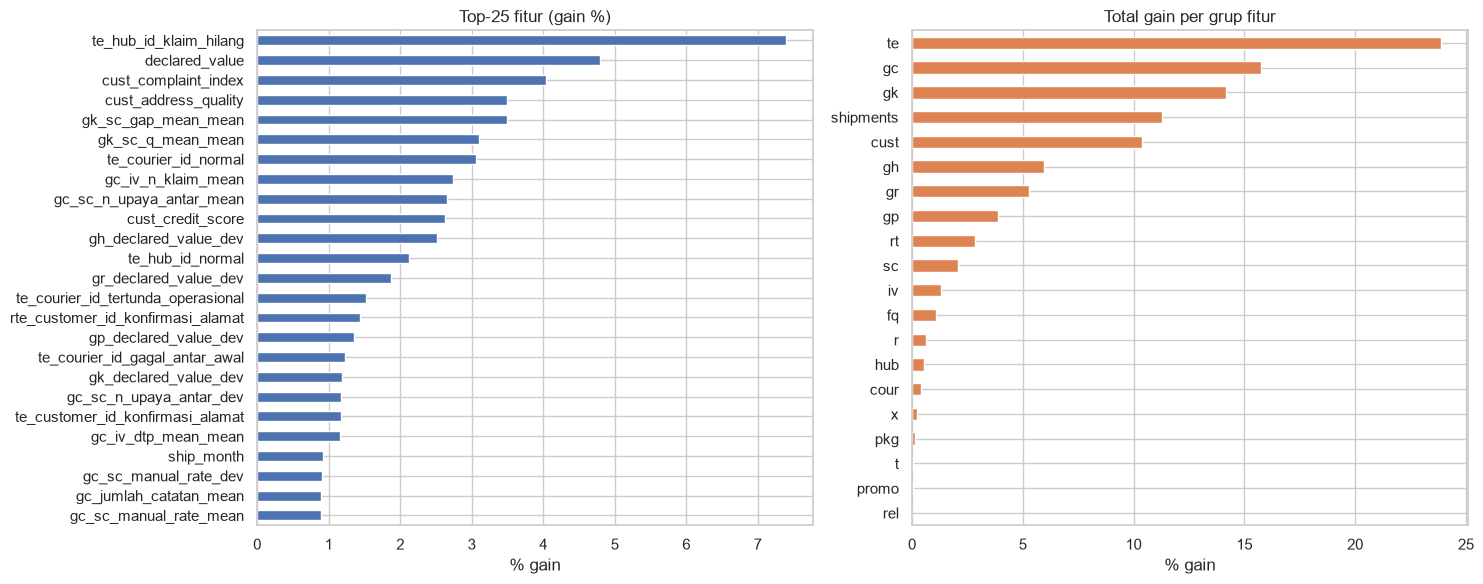

Rank kolom noise (dari 568 fitur): {'skor_prioritas_kirim': 199, 'indeks_rute_sekunder': 169, 'faktor_muatan_internal': 161, 'varian_cuaca_rute': 246, 'indeks_waktu_proses': 185, 'skor_kualitas_cek': 173}
Fitur dengan gain < 0,01%: 98


In [26]:
lgb_files = [f"{ART}/models/lgb_s0_f{k}.txt" for k in range(5)]
CAT_IMP = "cat_s11" if os.path.exists(f"{ART}/models/cat_s11_f0.cbm") else "cat_s0"  # model residual bila ada
cat_files = [f"{ART}/models/{CAT_IMP}_f{k}.cbm" for k in range(5)]


def with_te(df_rows: pl.DataFrame, X_rows: pd.DataFrame, k: int, feats: list) -> pd.DataFrame:
    # tempel tabel TE fold k (+ residual TE bila model memakainya) lalu urutkan kolom sesuai model
    Xk = apply_te_tables(df_rows, X_rows, f"{ART}/te/te_f{k}.parquet")
    if any(f.startswith("rte_") for f in feats):
        Xk = apply_te_tables(df_rows, Xk, f"{ART}/te/rte_f{k}.parquet", RESID_KEYS)
    return Xk[feats]
imp = None
if all(os.path.exists(f) for f in lgb_files):
    boosters = [lgb.Booster(model_file=f) for f in lgb_files]
    imp = pd.DataFrame({"feat": boosters[0].feature_name(),
                        "gain": np.mean([b.feature_importance("gain") for b in boosters], 0)})
    imp_src = "LightGBM (gain)"
elif all(os.path.exists(f) for f in cat_files):
    from catboost import CatBoostClassifier
    cms = [CatBoostClassifier().load_model(f) for f in cat_files]
    imp = pd.DataFrame({"feat": cms[0].feature_names_,
                        "gain": np.mean([m.get_feature_importance() for m in cms], 0)})
    imp_src = f"CatBoost {CAT_IMP} (PredictionValuesChange)"
if imp is not None:
    print("Sumber importance:", imp_src)
    imp["pct"] = imp.gain / imp.gain.sum() * 100
    imp = imp.sort_values("pct", ascending=False).reset_index(drop=True)
    pre = imp.feat.str.split("_").str[0]
    imp["grup"] = np.where(pre.isin(["te", "gc", "gk", "gh", "gr", "gp", "sc", "rt", "iv", "cust", "cour", "hub",
                                     "pkg", "promo", "fq", "x", "r", "rel", "t"]), pre, "shipments")
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    imp.head(25).iloc[::-1].plot.barh(x="feat", y="pct", ax=ax[0], legend=False, color="#4C72B0")
    ax[0].set(title="Top-25 fitur (gain %)", xlabel="% gain", ylabel="")
    imp.groupby("grup").pct.sum().sort_values().plot.barh(ax=ax[1], color="#DD8452")
    ax[1].set(title="Total gain per grup fitur", xlabel="% gain", ylabel="")
    plt.tight_layout(); plt.show()
    noise = ["skor_prioritas_kirim", "indeks_rute_sekunder", "faktor_muatan_internal", "varian_cuaca_rute",
             "indeks_waktu_proses", "skor_kualitas_cek"]
    print("Rank kolom noise (dari", len(imp), "fitur):",
          {c: int(imp.index[imp.feat == c][0]) + 1 for c in noise if c in set(imp.feat)})
    print(f"Fitur dengan gain < 0,01%: {(imp.pct < 0.01).sum()}")
else:
    print("Model belum tersedia — jalankan MODE='train' terlebih dulu.")

**Keputusan:** fitur tidak dipangkas. Kolom noise dan fitur ber-gain sangat kecil sudah jarang dipakai model
(dengan `feature_fraction=0.3` dan `min_data_in_leaf=400`, split pada noise hampir tidak memberi gain). Membuangnya
tidak memberi perubahan yang lebih besar dari variasi antar-fold, dan menambah risiko *selection bias* terhadap CV.
Grup fitur paling bernilai: **target encoding** dan **statistik grup kurir/customer**, sesuai temuan EDA 2.2.

## 9. Model & Training
Tiga GBDT dengan parameter yang dipilih dari eksperimen Section 7 (regularisasi kuat + early stopping 200 ronde
di fold validasi). Tanpa `class_weight` saat training: proba tetap terkalibrasi (baik untuk blending), lalu
Macro F1 dioptimasi lewat bobot kelas pasca-training (Section 11).

| Model | Catatan |
|---|---|
| LightGBM | `lr=0.03`, 63 leaves, `min_data_in_leaf=400`, `feature_fraction=0.3`, λ₂=10 |
| XGBoost | `hist`, depth 8, `colsample=0.4`, λ=10 (GPU opsional) |
| CatBoost | depth 8, `lr=0.08`, kategori native (*ordered target statistics*), GPU opsional |

In [27]:
LGB_PARAMS = dict(objective="multiclass", num_class=K, learning_rate=0.03, num_leaves=63, min_data_in_leaf=400,
                  feature_fraction=0.3, bagging_fraction=0.8, bagging_freq=1, lambda_l2=10.0, max_bin=255,
                  cat_smooth=20, max_cat_to_onehot=8, verbose=-1, num_threads=10)


XGB_PARAMS = dict(objective="multi:softprob", num_class=K, eta=0.05, max_depth=8, min_child_weight=20,
                  subsample=0.8, colsample_bytree=0.4, reg_lambda=10.0, tree_method="hist", max_bin=255,
                  eval_metric="mlogloss", nthread=10, max_cat_to_onehot=8)


CAT_PARAMS = dict(loss_function="MultiClass", learning_rate=0.08, depth=8, l2_leaf_reg=5, iterations=4000,
                  od_type="Iter", od_wait=150, border_count=128, verbose=500)


if os.environ.get("USE_GPU") == "1":  # CatBoost & XGBoost di GPU (NVIDIA + CUDA)
    CAT_PARAMS.update(task_type="GPU", devices="0")
    XGB_PARAMS.update(device="cuda")
else:
    CAT_PARAMS.update(thread_count=os.cpu_count())


def fit_predict(model: str, Xtr, ytr, Xva, yva, Xte, seed: int, path: str):
    if model == "lgb":
        import lightgbm as lgb
        dtr = lgb.Dataset(Xtr, ytr)
        dva = lgb.Dataset(Xva, yva, reference=dtr)
        m = lgb.train({**LGB_PARAMS, "seed": seed}, dtr, 20000, valid_sets=[dva],
                      callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(500)])
        m.save_model(path + ".txt", num_iteration=m.best_iteration)
        it = m.best_iteration
        return m, m.predict(Xva, num_iteration=it), m.predict(Xte, num_iteration=it), it
    if model == "xgb":
        import xgboost as xgb
        dtr = xgb.DMatrix(Xtr, ytr, enable_categorical=True)
        dva = xgb.DMatrix(Xva, yva, enable_categorical=True)
        m = xgb.train({**XGB_PARAMS, "seed": seed}, dtr, 20000, evals=[(dva, "va")], early_stopping_rounds=200,
                      verbose_eval=500)
        best = m.best_iteration + 1
        m = m[:best]  # simpan hanya pohon sampai best iteration
        m.save_model(path + ".json")
        return m, m.predict(dva), m.predict(xgb.DMatrix(Xte, enable_categorical=True)), best
    if model == "cat":
        from catboost import CatBoostClassifier, Pool
        cats = [c for c in Xtr.columns if str(Xtr[c].dtype) == "category"]
        conv = lambda d: d.assign(**{c: d[c].astype(str) for c in cats})
        ptr, pva = Pool(conv(Xtr), ytr, cat_features=cats), Pool(conv(Xva), yva, cat_features=cats)
        m = CatBoostClassifier(**CAT_PARAMS, random_seed=seed)
        m.fit(ptr, eval_set=pva, use_best_model=True)
        m.save_model(path + ".cbm")
        return m, m.predict_proba(pva), m.predict_proba(Pool(conv(Xte), cat_features=cats)), m.get_best_iteration()
    raise ValueError(model)


def load_predict(model: str, path: str, X: pd.DataFrame) -> np.ndarray:
    """Inference tanpa retrain: muat file model lalu prediksi proba."""
    if model == "lgb":
        import lightgbm as lgb
        return lgb.Booster(model_file=path + ".txt").predict(X)
    if model == "xgb":
        import xgboost as xgb
        b = xgb.Booster(); b.load_model(path + ".json")
        return b.predict(xgb.DMatrix(X, enable_categorical=True))
    if model == "cat":
        from catboost import CatBoostClassifier, Pool
        m = CatBoostClassifier(); m.load_model(path + ".cbm")
        cats = [c for c in X.columns if str(X[c].dtype) == "category"]
        return m.predict_proba(Pool(X.assign(**{c: X[c].astype(str) for c in cats}), cat_features=cats))
    raise ValueError(model)


def run_cv(model: str, seed: int, df_keys: pl.DataFrame, X: pd.DataFrame, y_all: np.ndarray, tr_all: np.ndarray,
           te_all: np.ndarray, codes: dict, folds: np.ndarray, art: str = "artifacts", quick: bool = False,
           rcodes: dict | None = None, R_all: np.ndarray | None = None):
    """Training 5-fold untuk satu model. Simpan model per fold, tabel TE, OOF & proba test.

    rcodes/R_all (opsional): tambah residual TE (RESID_KEYS) â†’ tabel di te/rte_f{k}_*.parquet.
    Urutan fitur model disimpan di features_{model}_s{seed}.json.
    """
    import gc, json, time
    os.makedirs(f"{art}/models", exist_ok=True)
    os.makedirs(f"{art}/te", exist_ok=True)
    oof = np.zeros((len(tr_all), K), dtype=np.float32)
    test_p = np.zeros((len(te_all), K), dtype=np.float32)
    log = []
    for k in range(1 if quick else int(folds.max()) + 1):
        t0 = time.time()
        tr_idx, va_idx = tr_all[folds != k], tr_all[folds == k]
        if quick:  # smoke test: 100rb baris saja
            tr_idx = np.random.default_rng(0).choice(tr_idx, 100_000, replace=False)
        Xtr, Xva, Xte = X.iloc[tr_idx].copy(), X.iloc[va_idx].copy(), X.iloc[te_all].copy()
        tables = add_te([Xtr, Xva, Xte], codes, y_all, tr_idx, [va_idx, te_all], seed=k, keep_tables=True)
        if not quick and not os.path.exists(f"{art}/te/te_f{k}_customer_id.parquet"):
            save_te_tables(df_keys, codes, tables, f"{art}/te/te_f{k}.parquet")
        if rcodes is not None:
            rtables = add_resid([Xtr, Xva, Xte], rcodes, R_all, tr_idx, [va_idx, te_all], seed=k, keep_tables=True)
            if not quick:
                save_te_tables(df_keys, rcodes, rtables, f"{art}/te/rte_f{k}.parquet", RESID_KEYS, "rte")
        if k == 0 and not quick:
            if rcodes is None:
                json.dump(list(Xtr.columns), open(f"{art}/features.json", "w"))
            json.dump(list(Xtr.columns), open(f"{art}/features_{model}_s{seed}.json", "w"))
        ytr, yva = y_all[tr_idx], y_all[va_idx]
        m, p_va, p_te, it = fit_predict(model, Xtr, ytr, Xva, yva, Xte, seed + k, f"{art}/models/{model}_s{seed}_f{k}")
        oof[folds == k], test_p = p_va, test_p + p_te / (int(folds.max()) + 1)
        r = dict(fold=k, iters=int(it), f1=macro_f1(yva, p_va), mins=round((time.time() - t0) / 60, 1))
        print(json.dumps(r), flush=True)
        log.append(r)
        del Xtr, Xva, Xte, m
        gc.collect()
    if quick:
        print("QUICK smoke test selesai â€” instalasi OK. Jalankan ulang tanpa QUICK=1 untuk training penuh.")
        return None
    y_tr = y_all[tr_all]
    summary = dict(model=model, seed=seed, f1_argmax=macro_f1(y_tr, oof), logloss=float(log_loss(y_tr, oof)),
                   fold_f1=[r["f1"] for r in log], fold_iters=[r["iters"] for r in log],
                   params={"lgb": LGB_PARAMS, "xgb": XGB_PARAMS, "cat": CAT_PARAMS}[model])
    print(json.dumps(summary), flush=True)
    np.save(f"{art}/oof_{model}_s{seed}.npy", oof)
    np.save(f"{art}/test_{model}_s{seed}.npy", test_p)
    json.dump(summary, open(f"{art}/summary_{model}_s{seed}.json", "w"), indent=1)
    return summary

In [28]:
if MODE == "train":
    key_cols = {c for cols, _ in TE_KEYS.values() for c in cols} | {c for cols, _ in RESID_KEYS.values() for c in cols}
    df_keys = df.select(sorted(key_cols))
    rcodes = te_codes(df, RESID_KEYS)
    np.save(f"{ART}/folds.npy", folds)
    if any(r for _, _, r, _ in MODEL_RUNS):  # tahap A residual TE (Section 6.1)
        np.save(f"{ART}/stageA_oof.npy", stage_a_oof(X, y_all, tr_all, folds, df))
    for model, seed, resid, override in MODEL_RUNS:
        print(f"===== {model} seed {seed} | residual TE={resid} | {override} =====")
        P = {"cat": CAT_PARAMS, "xgb": XGB_PARAMS, "lgb": LGB_PARAMS}[model]
        backup = dict(P); P.update(override)
        R_all = resid_matrix(y_all, tr_all, np.load(f"{ART}/stageA_oof.npy")) if resid else None
        run_cv(model, seed, df_keys, X, y_all, tr_all, te_all, codes, folds, ART,
               rcodes=rcodes if resid else None, R_all=R_all)
        P.clear(); P.update(backup)
else:
    print("MODE='inference' → training dilewati; memuat hasil CV tersimpan.")

runs = [(m, s) for m, s, *_ in MODEL_RUNS if os.path.exists(f"{ART}/oof_{m}_s{s}.npy")]
oofs = {f"{m}_s{s}": np.load(f"{ART}/oof_{m}_s{s}.npy") for m, s in runs}
cv_rows = []
for name, o in oofs.items():
    per_fold = [macro_f1(y_tr[folds == k], o[folds == k]) for k in range(5)]
    cv_rows.append(dict(model=name, logloss=round(log_loss(y_tr, o), 4), macro_f1=round(macro_f1(y_tr, o), 4),
                        f1_fold_std=round(np.std(per_fold), 4), **{f"f{k}": round(v, 4) for k, v in enumerate(per_fold)}))
pd.DataFrame(cv_rows)

MODE='inference' → training dilewati; memuat hasil CV tersimpan.


,model,logloss,macro_f1,f1_fold_std,f0,f1,f2,f3,f4
0,cat_s11,0.7786,0.6184,0.0009,0.6190,0.6174,0.6196,0.6173,0.6187
1,cat_s12,0.7795,0.6178,0.0011,0.6177,0.6169,0.6197,0.6165,0.6180
2,xgb_s11,0.7834,0.6160,0.0013,0.6167,0.6140,0.6178,0.6153,0.6162


## 10. Ensemble
Rata-rata **geometrik** proba (rata-rata log-proba lalu softmax) dengan bobot model dicari via minimisasi logloss
OOF: hanya *n_model − 1* parameter bebas, jadi risiko overfit minimal.

In [29]:
def blend(ps: list, w) -> np.ndarray:
    """Rata-rata geometrik berbobot dari beberapa matriks proba."""
    lp = sum(wi * np.log(np.clip(p, 1e-7, 1)) for wi, p in zip(w, ps))
    e = np.exp(lp - lp.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)


def fit_blend_weights(ps: list, y: np.ndarray) -> np.ndarray:
    """Bobot blend (softmax) yang meminimalkan logloss OOF."""
    from scipy.optimize import minimize
    if len(ps) == 1:
        return np.ones(1)
    obj = lambda a: log_loss(y, blend(ps, np.exp(a) / np.exp(a).sum()))
    a = minimize(obj, np.zeros(len(ps)), method="Nelder-Mead", options=dict(maxiter=200)).x
    return np.exp(a) / np.exp(a).sum()

In [30]:
names = list(oofs)
bw = fit_blend_weights([oofs[n] for n in names], y_tr)
oof_b = blend([oofs[n] for n in names], bw)
print("Bobot blend:", dict(zip(names, bw.round(3))))
print(f"Ensemble OOF: logloss={log_loss(y_tr, oof_b):.4f} | Macro F1 (argmax)={macro_f1(y_tr, oof_b):.4f}")

Bobot blend: {'cat_s11': np.float64(0.495), 'cat_s12': np.float64(0.225), 'xgb_s11': np.float64(0.281)}


Ensemble OOF: logloss=0.7775 | Macro F1 (argmax)=0.6186


## 11. Optimasi Macro F1 (bobot per kelas)
Argmax proba memaksimalkan *akurasi*, bukan Macro F1. Kita kalikan proba dengan bobot $w_k$ lalu argmax;
$w$ dicari dengan *coordinate ascent* pada grid log.

**Anti-overfit:** bobot dievaluasi secara **nested**: dicari di 4 fold OOF, diuji di fold ke-5 yang tidak ikut dipakai
mencarinya. Bobot final dicari di seluruh OOF (7 parameter dari 1,24 juta baris: risiko overfit sangat kecil).

In [31]:
def optimize_class_weights(proba, y, n_iter: int = 3, grid=None, sw=None) -> np.ndarray:
    """Coordinate ascent pada bobot multiplikatif per kelas (log-grid)."""
    grid = np.exp(np.linspace(-1.2, 1.2, 41)) if grid is None else grid
    w = np.ones(proba.shape[1])
    best = macro_f1(y, proba, w, sw)
    for _ in range(n_iter):
        for k in range(1, proba.shape[1]):  # kelas 0 jadi referensi
            cand = w.copy()
            scores = []
            for g in grid:
                cand[k] = w[k] * g
                scores.append(macro_f1(y, proba, cand, sw))
            j = int(np.argmax(scores))
            if scores[j] > best:
                best, w[k] = scores[j], w[k] * grid[j]
        grid = np.exp(np.linspace(-0.3, 0.3, 21))
    return w / w.sum() * len(w)

In [32]:
nested = []
for k in range(5):
    w_k = optimize_class_weights(oof_b[folds != k], y_tr[folds != k])
    nested.append(dict(fold=k, f1_argmax=macro_f1(y_tr[folds == k], oof_b[folds == k]),
                       f1_weighted=macro_f1(y_tr[folds == k], oof_b[folds == k], w_k), **dict(zip(CLASSES, w_k.round(2)))))
nested = pd.DataFrame(nested)
display(nested.round(4))
print(f"NESTED Macro F1: argmax {nested.f1_argmax.mean():.4f} ± {nested.f1_argmax.std():.4f} → "
      f"berbobot {nested.f1_weighted.mean():.4f} ± {nested.f1_weighted.std():.4f}")
CLASS_W = optimize_class_weights(oof_b, y_tr)
print("Bobot kelas final:", dict(zip(CLASSES, CLASS_W.round(3))))
print(f"OOF Macro F1 dengan bobot final: {macro_f1(y_tr, oof_b, CLASS_W):.4f}")

,fold,f1_argmax,f1_weighted,normal,konfirmasi_alamat,tertunda_operasional,gagal_antar_awal,retur_pengirim,rusak_perjalanan,klaim_hilang
0,0,0.6189,0.6275,0.79,0.64,0.72,1.04,1.13,1.28,1.40
1,1,0.6173,0.6270,0.77,0.65,0.73,1.04,1.11,1.29,1.41
2,2,0.6202,0.6298,0.77,0.65,0.73,1.04,1.11,1.29,1.41
3,3,0.6174,0.6281,0.81,0.68,0.68,1.09,1.16,1.23,1.35
4,4,0.6193,0.6286,0.81,0.68,0.66,1.06,1.13,1.27,1.39


NESTED Macro F1: argmax 0.6186 ± 0.0013 → berbobot 0.6282 ± 0.0011


Bobot kelas final: {'normal': np.float64(0.792), 'konfirmasi_alamat': np.float64(0.662), 'tertunda_operasional': np.float64(0.703), 'gagal_antar_awal': np.float64(1.069), 'retur_pengirim': np.float64(1.135), 'rusak_perjalanan': np.float64(1.28), 'klaim_hilang': np.float64(1.359)}
OOF Macro F1 dengan bobot final: 0.6286


**Cek pergeseran bulan (Section 2.1).** Apakah bobot kelas perlu disetel dengan baris OOF yang diberi *importance
weight* P_test(bulan)/P_train(bulan)? Bobot ini hanya memakai fitur test, bukan label. Diuji secara nested dan
dievaluasi pada distribusi bulan ala test.

In [33]:
def month_shift_weights(month_train: np.ndarray, month_test: np.ndarray) -> np.ndarray:
    """Importance weight per baris train = P_test(bulan) / P_train(bulan). Hanya memakai fitur test, bukan label."""
    pt = np.bincount(month_train, minlength=13) / len(month_train)
    pe = np.bincount(month_test, minlength=13) / len(month_test)
    r = np.divide(pe, pt, out=np.ones_like(pe), where=pt > 0)
    return r[month_train]

In [34]:
SW = month_shift_weights(df["ship_month"].to_numpy()[tr_all], df["ship_month"].to_numpy()[te_all])
rows = []
for k in range(5):
    a, b = folds != k, folds == k
    w_plain = optimize_class_weights(oof_b[a], y_tr[a])
    w_month = optimize_class_weights(oof_b[a], y_tr[a], sw=SW[a])
    rows.append(dict(fold=k, bobot_biasa=macro_f1(y_tr[b], oof_b[b], w_plain, SW[b]),
                     bobot_bulan=macro_f1(y_tr[b], oof_b[b], w_month, SW[b])))
shift = pd.DataFrame(rows)
display(shift.round(4))
print(f"Selisih rata-rata (bulan − biasa): {(shift.bobot_bulan - shift.bobot_biasa).mean():+.4f} "
      f"→ jauh di bawah std antar fold; dipakai bobot biasa (lebih sederhana)")

,fold,bobot_biasa,bobot_bulan
0,0,0.6274,0.6278
1,1,0.6271,0.6272
2,2,0.6299,0.6299
3,3,0.6280,0.6280
4,4,0.6286,0.6292


Selisih rata-rata (bulan − biasa): +0.0003 → jauh di bawah std antar fold; dipakai bobot biasa (lebih sederhana)


### 11.1 Matriks keputusan penuh
Bobot diagonal hanya menggeser skor tiap kelas secara independen. Untuk metrik *fractional-linear* seperti Macro F1,
klasifikasi optimal Bayes berbentuk $\arg\max_j (P\,W)_j$ dengan $W$ matriks **penuh**
([Narasimhan et al., ICML 2015](https://proceedings.mlr.press/v37/narasimhanb15.html)). Elemen $W_{ij}$ (i≠j)
mengizinkan proba kelas *i* ikut mendorong/menahan kelas *j* (mis. kelas yang sering tertukar).
$W$ dimulai dari `diag(CLASS_W)` lalu disempurnakan dengan *coordinate ascent*. Divalidasi **nested** seperti di atas.

In [35]:
def f1_matrix(y, proba, W, sw=None) -> float:
    """Macro F1 dari aturan keputusan linear umum: argmax(proba @ W)."""
    return macro_f1(y, proba @ W, None, sw)


def optimize_decision_matrix(proba, y, w_diag, n_iter: int = 2) -> np.ndarray:
    """Aturan keputusan optimal Macro F1 berbentuk argmax(PÂ·W) dengan W matriks penuh (Narasimhan et al., 2015).

    Mulai dari diag(w_diag) (bobot kelas), lalu coordinate ascent pada elemen off-diagonal W[i, j]
    (kontribusi proba kelas i ke skor kelas j), langkah relatif terhadap W[j, j].
    """
    W = np.diag(np.asarray(w_diag, dtype=np.float64)).astype(np.float32)
    p = proba.astype(np.float32)
    best = f1_matrix(y, p, W)
    grid = np.linspace(-0.3, 0.3, 13)
    for _ in range(n_iter):
        for i in range(W.shape[0]):
            for j in range(W.shape[0]):
                if i == j:
                    continue
                base, scores = W[i, j], []
                for g in grid:
                    W[i, j] = base + g * W[j, j]
                    scores.append(f1_matrix(y, p, W))
                b = int(np.argmax(scores))
                if scores[b] > best + 1e-6:
                    best, W[i, j] = scores[b], base + grid[b] * W[j, j]
                else:
                    W[i, j] = base
        grid = grid / 3
    return W

In [36]:
from joblib import Parallel, delayed

def _nested_matrix(k):
    a, b = folds != k, folds == k
    w_k = optimize_class_weights(oof_b[a], y_tr[a])
    W_k = optimize_decision_matrix(oof_b[a], y_tr[a], w_k)
    return dict(fold=k, diagonal=macro_f1(y_tr[b], oof_b[b], w_k), matriks=f1_matrix(y_tr[b], oof_b[b], W_k))

nested_m = pd.DataFrame(Parallel(n_jobs=5)(delayed(_nested_matrix)(k) for k in range(5)))
nested_m["selisih"] = nested_m.matriks - nested_m.diagonal
display(nested_m.round(4))
print(f"NESTED Macro F1: diagonal {nested_m.diagonal.mean():.4f} → matriks {nested_m.matriks.mean():.4f} "
      f"({nested_m.selisih.mean():+.4f} ± {nested_m.selisih.std():.4f}, naik di {(nested_m.selisih > 0).sum()}/5 fold)")
DECISION_W = optimize_decision_matrix(oof_b, y_tr, CLASS_W)
print(f"OOF Macro F1 dengan matriks final: {f1_matrix(y_tr, oof_b, DECISION_W):.4f}")
display(pd.DataFrame(DECISION_W, index=CLASSES, columns=CLASSES).round(3))

,fold,diagonal,matriks,selisih
0,0,0.6275,0.6293,0.0018
1,1,0.6270,0.6277,0.0007
2,2,0.6298,0.6301,0.0003
3,3,0.6281,0.6296,0.0015
4,4,0.6286,0.6306,0.0019


NESTED Macro F1: diagonal 0.6282 → matriks 0.6294 (+0.0012 ± 0.0007, naik di 5/5 fold)


OOF Macro F1 dengan matriks final: 0.6302


,normal,konfirmasi_alamat,tertunda_operasional,gagal_antar_awal,retur_pengirim,rusak_perjalanan,klaim_hilang
normal,0.792,0.198,0.187,0.160,0.114,0.064,0.068
konfirmasi_alamat,0.000,0.662,0.035,0.000,0.000,0.043,-0.068
tertunda_operasional,0.026,0.000,0.703,0.000,0.000,-0.149,-0.068
gagal_antar_awal,0.000,0.000,-0.117,1.069,0.000,0.000,0.000
retur_pengirim,-0.053,0.000,-0.012,0.000,1.135,0.000,0.068
rusak_perjalanan,-0.238,0.000,-0.012,0.000,0.038,1.280,0.000
klaim_hilang,0.000,-0.011,0.000,0.000,0.000,-0.384,1.359


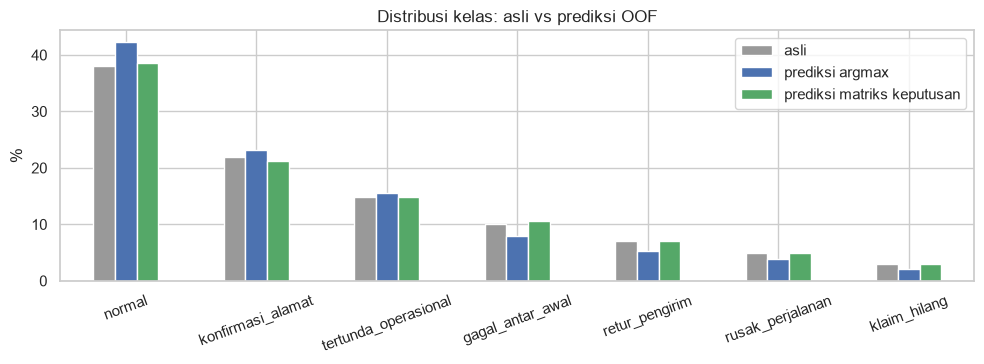

In [37]:
pred_oof = (oof_b @ DECISION_W).argmax(1)
cmp = pd.DataFrame({"asli": np.bincount(y_tr, minlength=K) / len(y_tr),
                    "prediksi argmax": np.bincount(oof_b.argmax(1), minlength=K) / len(y_tr),
                    "prediksi matriks keputusan": np.bincount(pred_oof, minlength=K) / len(y_tr)}, index=CLASSES)
ax = (cmp * 100).plot.bar(figsize=(10, 3.8), rot=20, color=["#999999", "#4C72B0", "#55A868"])
ax.set(title="Distribusi kelas: asli vs prediksi OOF", ylabel="%"); plt.tight_layout(); plt.show()

Bobot kelas menggeser prediksi dari `normal` ke kelas minoritas, mendekati distribusi asli. Inilah yang diinginkan Macro F1.

## 12. Analisis Error

                      precision    recall  f1-score   support

              normal     0.8165    0.8263    0.8214    473531
   konfirmasi_alamat     0.7311    0.7047    0.7177    272911
tertunda_operasional     0.7678    0.7650    0.7664    185496
    gagal_antar_awal     0.4861    0.5180    0.5016    124341
      retur_pengirim     0.5393    0.5340    0.5366     87740
    rusak_perjalanan     0.5509    0.5395    0.5451     61942
        klaim_hilang     0.5309    0.5147    0.5227     37656

            accuracy                         0.7153   1243617
           macro avg     0.6318    0.6289    0.6302   1243617
        weighted avg     0.7160    0.7153    0.7156   1243617



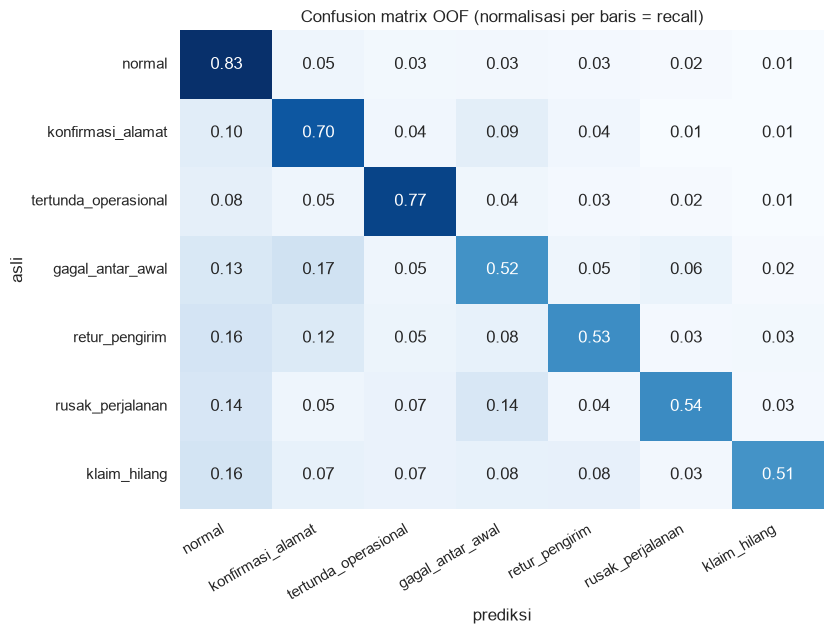

In [38]:
print(classification_report(y_tr, pred_oof, target_names=CLASSES, digits=4))
cm = confusion_matrix(y_tr, pred_oof, normalize="true")
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
ax.set(title="Confusion matrix OOF (normalisasi per baris = recall)", xlabel="prediksi", ylabel="asli")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

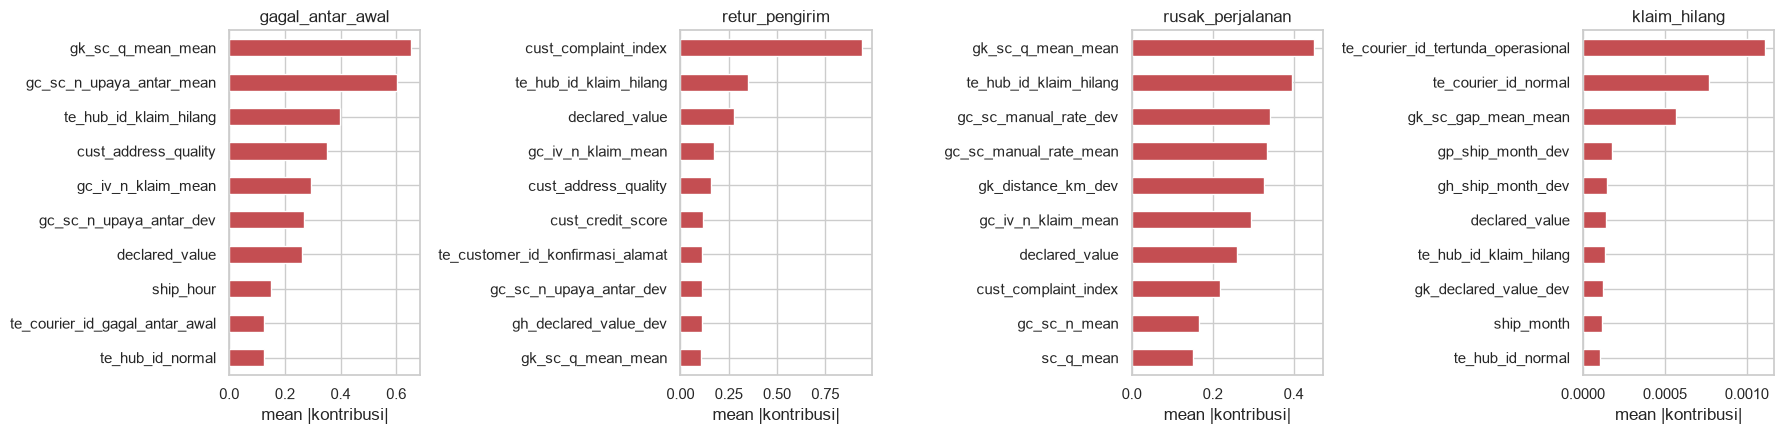

In [39]:
# Kontribusi fitur (TreeSHAP bawaan LightGBM / CatBoost) untuk kelas-kelas tersulit, sampel baris validasi fold 0
contrib = None
if all(os.path.exists(f) for f in lgb_files):
    va0 = tr_all[folds == 0][:4000]
    Xs = apply_te_tables(df[va0], X.iloc[va0], f"{ART}/te/te_f0.parquet")[boosters[0].feature_name()]
    contrib = boosters[0].predict(Xs, pred_contrib=True).reshape(len(Xs), K, -1)[:, :, :-1]
elif all(os.path.exists(f) for f in cat_files):
    from catboost import Pool
    va0 = tr_all[folds == 0][:2000]
    Xs = with_te(df[va0], X.iloc[va0], 0, cms[0].feature_names_)
    cats = [c for c in Xs.columns if str(Xs[c].dtype) == "category"]
    pool = Pool(Xs.assign(**{c: Xs[c].astype(str) for c in cats}), cat_features=cats)
    contrib = cms[0].get_feature_importance(pool, type="ShapValues")[:, :, :-1]  # (n, K, fitur)
if contrib is not None:
    focus = ["gagal_antar_awal", "retur_pengirim", "rusak_perjalanan", "klaim_hilang"]
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    for ax, c in zip(axes, focus):
        s = pd.Series(np.abs(contrib[:, CLS_IDX[c]]).mean(0), index=Xs.columns).nlargest(10)[::-1]
        s.plot.barh(ax=ax, color="#C44E52"); ax.set_title(c); ax.set_xlabel("mean |kontribusi|")
    plt.tight_layout(); plt.show()

**Catatan:** TE pada baris validasi fold 0 di sel ini memakai tabel TE fold 0 (dari bagian train fold 0),
sama seperti saat validasi, jadi tidak ada kebocoran.

## 13. Simpan Model & Artefak
| File | Isi |
|---|---|
| `artifacts/models/lgb_s0_f{k}.txt`, `cat_s0_f{k}.cbm`, `xgb_s0_f{k}.json` | model per fold (5 × 3) |
| `artifacts/te/te_f{k}_{kunci}.parquet` | tabel target encoding per fold |
| `artifacts/folds.npy` | pembagian fold |
| `artifacts/oof_*.npy`, `test_*.npy` | proba OOF & test per model (untuk blending & cek reproducibility) |
| `artifacts/ensemble.json` | daftar model, bobot blend, bobot kelas, matriks keputusan, skor CV |

In [40]:
ensemble_cfg = dict(models=names, blend_weights=bw.tolist(), class_weights=CLASS_W.tolist(),
                    decision_matrix=DECISION_W.tolist(), classes=CLASSES,
                    oof_logloss=float(log_loss(y_tr, oof_b)), oof_macro_f1=float(f1_matrix(y_tr, oof_b, DECISION_W)),
                    nested_macro_f1_diag=float(nested.f1_weighted.mean()),
                    nested_macro_f1=float(nested_m.matriks.mean()), nested_std=float(nested_m.matriks.std()))
json.dump(ensemble_cfg, open(f"{ART}/ensemble.json", "w"), indent=1)  # deterministik dari OOF tersimpan
ensemble_cfg = json.load(open(f"{ART}/ensemble.json"))                 # inference di bawah hanya membaca file ini
sizes = {}
for root, _, files in os.walk(ART):
    for f in files:
        sizes[os.path.relpath(os.path.join(root, f), ART)] = os.path.getsize(os.path.join(root, f)) / 1e6
print(f"{len(sizes)} file artefak, total {sum(sizes.values()):.0f} MB")
print(json.dumps({k: v for k, v in ensemble_cfg.items() if k != "classes"}, indent=1))

112 file artefak, total 3702 MB
{
 "models": [
  "cat_s11",
  "cat_s12",
  "xgb_s11"
 ],
 "blend_weights": [
  0.4949298609045842,
  0.22454055764505393,
  0.2805295814503618
 ],
 "class_weights": [
  0.7920827809519901,
  0.6616031519009969,
  0.7025144059980798,
  1.069199918197338,
  1.1353155487052422,
  1.280064706714272,
  1.3592194875320809
 ],
 "decision_matrix": [
  [
   0.7920827865600586,
   0.19848094880580902,
   0.18733717501163483,
   0.16037999093532562,
   0.11353155225515366,
   0.06400323659181595,
   0.06796097010374069
  ],
  [
   7.450580707946131e-10,
   0.6616031527519226,
   0.035125721246004105,
   0.0,
   0.0,
   0.04266882315278053,
   -0.06796097010374069
  ],
  [
   0.026402760297060013,
   0.0,
   0.7025144100189209,
   0.0,
   0.0,
   -0.14934088289737701,
   -0.06796097010374069
  ],
  [
   0.0,
   0.0,
   -0.11708573251962662,
   1.0691999197006226,
   0.0,
   0.0,
   0.0
  ],
  [
   -0.05280551686882973,
   0.0,
   -0.011708573438227177,
   0.0,
   1.

## 14. Inferensi Tanpa Retrain → `submission.csv`
Bagian ini **hanya memuat file**: model per fold + tabel TE per fold + konfigurasi ensemble. Pipeline fitur test
adalah fungsi `build()` yang sama dengan train. Alur per model: untuk tiap fold *k*, tempel TE fold *k* → muat model
fold *k* → proba, lalu rata-rata 5 fold → blend geometrik → × matriks keputusan W → argmax.

In [41]:
def predict_test(df: pl.DataFrame, X: pd.DataFrame, te_all: np.ndarray, cfg: dict) -> tuple[np.ndarray, dict]:
    df_te, X_te = df[te_all], X.iloc[te_all]
    probs = {}
    for name in cfg["models"]:
        model, seed = name.rsplit("_s", 1)
        ff = f"{ART}/features_{name}.json"  # urutan fitur per model (model residual punya kolom rte_*)
        features = json.load(open(ff if os.path.exists(ff) else f"{ART}/features.json"))
        p = np.zeros((len(te_all), K))
        for k in range(5):
            Xk = with_te(df_te, X_te, k, features)
            p += load_predict(model, f"{ART}/models/{model}_s{seed}_f{k}", Xk) / 5
        probs[name] = p
        print(f"✓ {name}: 5 fold diprediksi")
    pb = blend([probs[n] for n in cfg["models"]], cfg["blend_weights"])
    return (pb @ np.array(cfg["decision_matrix"], dtype=np.float32)).argmax(1), probs


t0 = time.time()
pred_test, test_probs = predict_test(df, X, te_all, ensemble_cfg)
sub = pd.DataFrame({"shipment_id": df["shipment_id"].to_numpy()[te_all],
                    "status_penanganan": np.array(CLASSES)[pred_test]})
sub.to_csv(SUBMISSION_PATH, index=False)
print(f"inference {time.time() - t0:.0f}s → {SUBMISSION_PATH}")

✓ cat_s11: 5 fold diprediksi


✓ cat_s12: 5 fold diprediksi


✓ xgb_s11: 5 fold diprediksi


inference 205s → submission.csv


In [42]:
# Validasi format submission
ss = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
assert len(sub) == len(ss) == 362_245, "jumlah baris salah"
assert (sub.shipment_id.values == ss.shipment_id.values).all(), "urutan shipment_id beda dari sample_submission"
assert sub.status_penanganan.isin(CLASSES).all() and sub.shipment_id.is_unique
print("✓ format submission valid")

# Reproducibility: proba hasil inference == proba test yang disimpan saat training
for name, p in test_probs.items():
    ref = f"{ART}/test_{name}.npy"
    if os.path.exists(ref):
        print(f"{name}: max |diff| vs saat training = {np.abs(p - np.load(ref)).max():.2e}")
display(sub.status_penanganan.value_counts(normalize=True).round(4).to_frame("proporsi"))
sub.head()

✓ format submission valid
cat_s11: max |diff| vs saat training = 0.00e+00


cat_s12: max |diff| vs saat training = 0.00e+00
xgb_s11: max |diff| vs saat training = 1.34e-07


,proporsi
status_penanganan,
normal,0.3783
konfirmasi_alamat,0.2098
tertunda_operasional,0.1526
gagal_antar_awal,0.1067
retur_pengirim,0.0721
rusak_perjalanan,0.0508
klaim_hilang,0.0296


,shipment_id,status_penanganan
0,SHP-5A64RENJ,normal
1,SHP-BUZSJTV9,konfirmasi_alamat
2,SHP-EGUZBJHQ,rusak_perjalanan
3,SHP-YWBRSQLZ,konfirmasi_alamat
4,SHP-JS89CKME,tertunda_operasional


## 15. Ringkasan & Dependensi

### Hasil
Tabel CV per model (Section 9), ensemble (Section 10), dan **Macro F1 nested** (Section 11) adalah estimasi skor
private yang paling jujur. Seluruh keputusan diambil dari CV lokal, **bukan** public LB (hanya 30% test).

### 2 final pick
1. **Ensemble residual**: CatBoost lr 0,02 + CatBoost lr 0,04 + XGBoost, semuanya dengan residual TE customer,
   + matriks keputusan (CV terbaik, nested Macro F1 ±0,6294).
2. **Hedge tanpa residual TE**: CatBoost (3 varian) + XGBoost + matriks keputusan (nested ±0,6283), untuk berjaga
   seandainya residual TE berperilaku berbeda di data test.

| Tahap | Nested Macro F1 |
|---|---:|
| CatBoost lr 0,08 + bobot kelas diagonal | 0,6256 |
| + XGBoost (ensemble) | 0,6267 |
| + matriks keputusan penuh + CatBoost lr kecil | 0,6283 |
| **+ residual TE customer (final)** | **0,6294** |

LightGBM (`src/train.py lgb 0`) bisa ditambahkan ke `MODEL_RUNS`; notebook otomatis memakainya jika artefaknya ada.

### Anti-overfit checklist
- [x] Semua yang memakai target (TE, bobot blend, bobot kelas) dihitung di dalam fold / divalidasi nested
- [x] Statistik grup & frequency encoding tidak memakai label
- [x] Early stopping pada fold validasi; regularisasi kuat (min_data_in_leaf 400, λ=10, colsample 0,3)
- [x] Keputusan berdasarkan CV mean ± std; perubahan < std antar fold dianggap tidak ada
- [x] Adversarial validation memastikan train/test sebanding
- [x] Tidak ada tuning ke public LB

### Cara menjalankan
```bash
pip install -r requirements.txt
export KAGGLE_KEY=...; python data.py          # data → data/
# opsi A: notebook ini dengan MODE="inference" (butuh folder artifacts/)
# opsi B: latih ulang lewat script
python src/train.py lgb 0
USE_GPU=1 python src/train.py cat 0
USE_GPU=1 python src/train.py xgb 0
```

### Dependensi
Python 3.12 · numpy 2.5.5 · pandas 3.1.1 · polars 2.1.0 · pyarrow 26.0.1 · scipy 1.18.1 · scikit-learn 1.9.1 ·
lightgbm 4.7.0 · xgboost 3.4.1 · catboost 1.2.10 · matplotlib 3.11.2 · seaborn 0.13.2.
Tidak memakai model pre-trained / LLM eksternal. Semua model dilatih sendiri dari data kompetisi.